# Gnani Prisma + Timbre: complete public evaluation

This notebook documents and **replays the completed public tests from setup to final conclusions**. Every executed code cell retains its output. Live collection took place earlier; this walkthrough makes **zero paid model/API calls**. Saved audio, actual API responses, frozen source references and real human marks are included under `evidence/`.

Read `report.pdf` for the two-page assessment and open `submission.html` for the detailed interactive audio/transcript gallery. `HTML_PLAN.md` records the page plan made before implementation. Private recordings/call transcripts, credentials and personal spending notes are excluded.

Evidence tiers remain separate: source-reference ASR; selected human TTS marks; diagnostic waveform/network measurements; provisional audio-model observations; and prepared but uncollected new human ratings. No generated audio or blank template is called a completed human score.

## 0. Environment, saved evidence and replay guard
**Method:** locate the bundled source, disable live mode, remove API credentials from the replay environment, run the same published scoring/report entry point, and load its outputs. The CLI includes count reconciliation and regenerates the controlled five-repeat comparison.
**Output:** environment/version, zero-call flag and reconciled benchmark summary. Documented dependencies are pinned in `evidence/requirements-lock.txt`.

In [1]:
from pathlib import Path
import os, sys, json, csv, subprocess, hashlib, inspect
import pandas as pd
from IPython.display import display, HTML, Markdown, Audio, Image
ROOT = Path.cwd()
EVIDENCE = ROOT / "evidence"
assert (EVIDENCE / "run_evaluation.py").is_file(), "Start Jupyter in GA_Submission."
assert not (EVIDENCE / ".env").exists(), "This submission replays without a credentials file."
os.environ["GNANI_LIVE"] = "0"
for name in ["GNANI_API_KEY", "GEMINI_API_KEY", "GOOGLE_API_KEY"]:
    os.environ.pop(name, None)
sys.path.insert(0, str(EVIDENCE))
sys.path.insert(0, str(EVIDENCE / "scripts"))
replay = subprocess.run([sys.executable, "run_evaluation.py", "--mode", "replay", "--part", "all", "--reports"], cwd=EVIDENCE, capture_output=True, text=True, encoding="utf8", errors="replace")
print(replay.stdout)
(ROOT/"assets/replay_output.txt").write_text(replay.stdout + replay.stderr, encoding="utf8")
if replay.returncode:
    print(replay.stderr)
assert replay.returncode == 0
S = json.loads((EVIDENCE / "results/submission/summary.json").read_text(encoding="utf8"))
D = json.loads((ROOT / "assets/submission_data.json").read_text(encoding="utf8"))
assert S["new_api_calls"] == 0
print({"Python": sys.version.split()[0], "profile": S["profile"], "new_api_calls": S["new_api_calls"], "catalog_records": len(D["catalog"])})
def rows(relative):
    with (EVIDENCE / relative).open(encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))
def show(data, columns=None):
    frame = data.copy() if isinstance(data, pd.DataFrame) else pd.DataFrame(data)
    if columns is not None:
        frame = frame.reindex(columns=columns)
    display(HTML('<div style="max-height:600px;overflow:auto;border:1px solid #d5dfe8;padding:8px">' + frame.to_html(index=False, escape=True, max_rows=None, max_cols=None) + '</div>'))
    print(f"All {len(frame)} rows displayed; scroll the output for the complete table.")
def listen(case_id, kind=None):
    matches=[r for r in D["catalog"] if r["id"] == case_id and (kind is None or r["kind"] == kind)]
    assert matches, case_id
    r=matches[0]
    display(Markdown(f"**{r['id']}** · {r['model']} · {r['language']}"))
    if r.get("audio"):
        display(Audio(filename=str(ROOT / r["audio"]), embed=True))
    return r

report.pdf: 2 pages; public ASR, human TTS scores and separate provisional audio-model follow-up
next_stages_report.pdf: 2 pages; public ASR, human TTS scores and separate provisional audio-model follow-up
Created C:\Users\saiaakash\Desktop\api_testing\GA_Submission\evidence\timbre_comparison.html: 18 embedded clips, 9 comparisons, 17.9 MB; no API calls
Public-dataset ASR / human-reviewed TTS all replay passed: results\submission

{'Python': '3.14.4', 'profile': 'public_submission', 'new_api_calls': 0, 'catalog_records': 1341}


## 1. Dataset scope, licenses, selection and input integrity
**Inputs:** 226 primary ASR inputs (221 speech + five no-speech), 120 follow-up inputs and 24 public extension inputs. Original sources include Google SVQ, FLEURS, MUSAN and MUCS. A later independent MInDS-14 banking cohort has 15 recordings, replayed under two hint conditions.
**Method:** verify every released primary input SHA-256; retain source, language, speaker and parent IDs. Cohorts do not repeat source utterances/audio, but speakers can overlap. Noise/codec derivatives are paired observations, not new speakers. Licenses and attribution are in `evidence/DATASETS.md`.
**Limits:** dataset reference errors can affect ASR scores. The held-out MInDS-14 recordings are 8 kHz US English, with unknown speaker identities; they are not Indian-accent population validation.

In [2]:
manifest = rows("results/submission/evidence_manifest.csv")
for r in manifest:
    assert hashlib.sha256((EVIDENCE / r["input_path"]).read_bytes()).hexdigest() == r["input_sha256"]
assert len(manifest) == 370
show([{"cohort": k, "inputs": v["selected_clips"], "speech": v["speech_clips"], "controls": v["no_speech_controls"], "reference_words": v["reference_words"]} for k,v in S["asr"].items()])
show(rows("results/submission/cohort_overlap.csv"))
show(manifest)

cohort,inputs,speech,controls,reference_words
baseline,226,221,5,1630
followup,120,120,0,881
public24,24,24,0,249


All 3 rows displayed; scroll the output for the complete table.


cohort_a,cohort_b,clip_id,input_sha256,source_ref,speaker_id
baseline,followup,0,0,0,43
baseline,public24,0,0,0,10
followup,public24,0,0,0,9


All 3 rows displayed; scroll the output for the complete table.


clip_id,cohort,language,speaker_id,source_dataset,source_ref,parent_clip_id,reference_source,input_path,input_sha256,input_integrity,scoring_eligible
CL-EN-01,baseline,en-IN,speaker_15117425685521502135,google/svq 1.0.0,utts_en_in_clean.parquet#utt_2378122408190210838,,original_dataset_text,data/audio/CL-EN-01.wav,1e8b757316e352e591040c982109bf9162174501cb161403a7db41963355eb0e,sha256_verified,True
CL-EN-02,baseline,en-IN,speaker_8706784997864741703,google/svq 1.0.0,utts_en_in_clean.parquet#utt_11255507015851828344,,original_dataset_text,data/audio/CL-EN-02.wav,c4a5683b64cc5df0bbbda810af4ade95fb057e6a011d3f562345f990f851c3c6,sha256_verified,True
CL-EN-03,baseline,en-IN,speaker_7113944816261864857,google/svq 1.0.0,utts_en_in_clean.parquet#utt_2642746554516430273,,original_dataset_text,data/audio/CL-EN-03.wav,b03ea8efbcc4cf1aacd87fc2c026ea6ae766c2ab51bf4bccfa08d04f3f00284d,sha256_verified,True
CL-EN-04,baseline,en-IN,speaker_9498065097818851968,google/svq 1.0.0,utts_en_in_clean.parquet#utt_11933578377211113668,,original_dataset_text,data/audio/CL-EN-04.wav,2f13a7c93ec6bd15d98cb365dfc20419b8bbb666881589b7b228644aecc29c59,sha256_verified,True
CL-EN-05,baseline,en-IN,speaker_11298494297948342752,google/svq 1.0.0,utts_en_in_clean.parquet#utt_11249219445497478910,,original_dataset_text,data/audio/CL-EN-05.wav,ee8cdeeabc164c1108c4094fcceaa13befd0f454acbb2cccb829c3c486348561,sha256_verified,True
CL-EN-06,baseline,en-IN,speaker_13289036129798759378,google/svq 1.0.0,utts_en_in_clean.parquet#utt_11194582731079507062,,original_dataset_text,data/audio/CL-EN-06.wav,1e96551f536a13340a1c3ffe54af41a8d024c077d86f81845b1b31b5c03a729a,sha256_verified,True
CL-HI-01,baseline,hi-IN,speaker_13289036129798759378,google/svq 1.0.0,utts_hi_in_clean.parquet#utt_3427604354974386008,,original_dataset_text,data/audio/CL-HI-01.wav,0b6276b2f7c3de0994a2b270b69dd375dd255cf657cce69e0f007587880b2029,sha256_verified,True
CL-HI-02,baseline,hi-IN,speaker_2006892072279700611,google/svq 1.0.0,utts_hi_in_clean.parquet#utt_16581489161115389334,,original_dataset_text,data/audio/CL-HI-02.wav,0d360eae2d74b221aad1e186cb706e448afdbf5efaab47ad2af85b590e1ab9b4,sha256_verified,True
CL-HI-03,baseline,hi-IN,speaker_11298494297948342752,google/svq 1.0.0,utts_hi_in_clean.parquet#utt_10764307002565399341,,original_dataset_text,data/audio/CL-HI-03.wav,59f0396dab69ef6dd4c58b29ca0a534a257bcdcfe4ccb4b000ba1d58a32c29e7,sha256_verified,True
CL-HI-04,baseline,hi-IN,speaker_7113944816261864857,google/svq 1.0.0,utts_hi_in_clean.parquet#utt_167285164136309557,,original_dataset_text,data/audio/CL-HI-04.wav,f8e921cc35520c36c1bb978a851d3dd5e6124eef591ae6bf78fd57882798de0b,sha256_verified,True


All 370 rows displayed; scroll the output for the complete table.


## 2. Pilot requests and request identity
**Method:** the saved public pilot established that a small ASR request returned text and a small TTS request returned decodable audio. Later collectors gated live requests, reused exact-fingerprint cache hits and saved responses before scoring.
**Output:** pilot request status, latency and effective configuration, without credentials. Billing observations are not part of the assignment report. A request ID identifies an attempt; case IDs, retries and separate rechecks have different meanings.

In [3]:
from build_submission import journal
pilot = [r for r in journal(EVIDENCE / "results/attempts.jsonl") if r.get("run_tag") == "pilot"]
show([{k:r.get(k) for k in ["kind", "case_id", "request_id", "http_status", "ok", "latency_ms", "settings"]} for r in pilot])
listen("CL-EN-01", "ASR")
show([r for r in D["catalog"] if r["id"] == "CL-EN-01"], ["id", "reference", "hypothesis", "wer", "latency_ms"])

kind,case_id,request_id,http_status,ok,latency_ms,settings
asr,CL-EN-01,CL-EN-01-pilot-a1-c00ce2cb,200,True,548.0,"{'endpoint': 'https://api.vachana.ai/stt/v3', 'model': 'prisma-v3.0', 'language_code': 'en-IN', 'format': 'transcribe'}"
tts,T31,T31-pilot-a1-7c6faa20,200,True,1937.3,"{'endpoint': 'https://api.vachana.ai/api/v1/tts/inference', 'voice': 'Tarika', 'model': 'timbre-v3.0', 'language': 'en-IN', 'speed': 1.0, 'audio_config': {'sample_rate': 24000, 'num_channels': 1, 'sample_width': 2, 'encoding': 'linear_pcm', 'container': 'wav'}}"


All 2 rows displayed; scroll the output for the complete table.


**CL-EN-01** · prisma-v3.0 · en-IN

id,reference,hypothesis,wer,latency_ms
CL-EN-01,Who first identified blood types?,Who first identified blood types?,0.0,701.7


All 1 rows displayed; scroll the output for the complete table.


## 3. WER/CER implementation and normalization
**Method:** custom Levenshtein dynamic programming, deterministic S/D/I alignment, Unicode NFC and case folding, Unicode digits and documented punctuation handling. Corpus WER sums word edits / reference words; CER counts Unicode code points, with and without spaces. Empty references are evaluated separately.
**Output:** the exact implementation used by replay and illustrative checks. Critical signs, digit order and leading zeros must not be silently collapsed.

In [4]:
from evaluation_metrics import normalize, edit_counts, score, corpus
print(inspect.getsource(normalize))
print(inspect.getsource(edit_counts))
print(inspect.getsource(score))
examples = [("the change was -2.5%", "the change was 2.5%"), ("reference 004291", "reference 4291"), ("buy 15 not 50", "buy 50 not 15"), ("", "unexpected words")]
show([{"reference": ref, "hypothesis": hyp, **score(ref,hyp)} for ref,hyp in examples])
assert score("reference 004291", "reference 4291")["word_edits"] == 1
assert score("", "unexpected words")["wer"] is None

def normalize(text, *, raw=False):
    text = " ".join(unicodedata.normalize('NFC', str(text)).casefold().split())
    if raw:
        return text
    text = text.replace('−', '-')
    text = ''.join(str(unicodedata.digit(c)) if c.isdigit() and unicodedata.digit(c, None) is not None else c for c in text)
    out = []
    for i, c in enumerate(text):
        prev, nxt = (text[i-1] if i else ''), (text[i+1] if i+1 < len(text) else '')
        keep = c in '%₹' or unicodedata.category(c)[0] in 'LNM' or c.isspace()
        keep |= c in '.:' and prev.isdigit() and nxt.isdigit()
        keep |= c == '-' and nxt.isdigit() and not prev.isalnum()
        out.append(c if keep else ' ')
    return ' '.join(''.join(out).split())

def edit_counts(ref, hyp):
    n, m = len(ref), len(hyp)
    dp = [[i+j if i*j == 0 else 0 for j in range(m+1)] for i in range(n+1)]
    for i in range(1, n+1):
        for j in range(1, m+1):
            dp[i][j] = min(dp[i-1][j]+1, dp[i][j-1]+1, dp[i-1][j-1]+(ref[i-1] !=

reference,hypothesis,reference_normalized,hypothesis_normalized,ref_word_count,word_edits,ref_char_count,char_edits,nospace_ref_chars,nospace_char_edits,substitutions,deletions,insertions,wer,cer,false_transcription,no_speech_inserted_words
the change was -2.5%,the change was 2.5%,the change was -2.5%,the change was 2.5%,4,1,20,1,17,1,1,0,0,0.25,0.050000,None,NaN
reference 004291,reference 4291,reference 004291,reference 4291,2,1,16,2,15,2,1,0,0,0.50,0.125000,None,NaN
buy 15 not 50,buy 50 not 15,buy 15 not 50,buy 50 not 15,4,2,13,4,10,4,2,0,0,0.50,0.307692,None,NaN
,unexpected words,,unexpected words,0,2,0,16,0,15,0,0,2,NaN,NaN,True,2.0


All 4 rows displayed; scroll the output for the complete table.


## 4. Primary ASR corpus and language/category results
**Method:** recompute all primary scores from frozen original source references and actual cached Gnani transcripts. Baseline/follow-up/extension are distinct convenience samples, not paired before/after model estimates.
**Output:** full per-clip records, corpus totals, languages and categories. Baseline is 309 edits / 1,630 reference words = 18.96% normalized WER; raw WER is retained separately.

In [5]:
ASR = rows("results/submission/asr_results.csv")
calculated = {k: corpus([r for r in ASR if r["cohort"] == k]) for k in S["asr"]}
show([{"cohort":k, **v} for k,v in calculated.items()])
assert calculated["baseline"]["word_edits"] == 309
assert calculated["baseline"]["reference_words"] == 1630
show([{"cohort":cohort, "language":language, **r} for cohort,v in S["asr"].items() for language,r in v["by_language"].items()])
category = []
for cohort in sorted({r["cohort"] for r in ASR}):
    for name in sorted({r["category"] for r in ASR if r["cohort"] == cohort}):
        category.append({"cohort":cohort,"category":name,**corpus([r for r in ASR if r["cohort"]==cohort and r["category"]==name])})
show(category)
show(ASR, ["clip_id","cohort","language","category","reference","hypothesis","substitutions","deletions","insertions","word_edits","ref_word_count","wer","cer","latency_ms","raw_response_path"])

cohort,speech_clips,reference_words,word_edits,wer,cer,cer_no_spaces
baseline,221,1630,309,0.189571,0.108805,0.120908
followup,120,881,186,0.211124,0.102546,0.108385
public24,24,249,48,0.192771,0.132475,0.141423


All 3 rows displayed; scroll the output for the complete table.


cohort,language,speech_clips,reference_words,word_edits,wer,cer,cer_no_spaces
baseline,en-IN,62,453,23,0.050773,0.025969,0.026536
baseline,hi-IN,61,580,129,0.222414,0.201897,0.242910
baseline,kn-IN,14,83,18,0.216867,0.050769,0.051635
baseline,mr-IN,14,100,30,0.300000,0.091181,0.092624
baseline,ta-IN,14,93,24,0.258065,0.089136,0.095462
baseline,te-IN,56,321,85,0.264798,0.104484,0.105765
followup,en-IN,20,148,21,0.141892,0.075965,0.077037
followup,hi-IN,20,192,17,0.088542,0.031959,0.037594
followup,kn-IN,20,136,48,0.352941,0.200380,0.215582
followup,mr-IN,20,164,38,0.231707,0.107244,0.112078


All 15 rows displayed; scroll the output for the complete table.


cohort,category,speech_clips,reference_words,word_edits,wer,cer,cer_no_spaces
baseline,clean_en,18,121,12,0.099174,0.063348,0.064286
baseline,clean_hi,17,152,25,0.164474,0.157161,0.188073
baseline,clean_kn,8,42,10,0.238095,0.034884,0.029032
baseline,clean_mr,8,46,12,0.260870,0.082508,0.083019
baseline,clean_ta,8,51,11,0.215686,0.088305,0.095745
baseline,clean_te,16,78,20,0.256410,0.085859,0.082707
baseline,long,4,89,14,0.157303,0.082883,0.091489
baseline,no_speech,0,0,0,NaN,NaN,NaN
baseline,numbers,32,268,52,0.194030,0.075875,0.079632
baseline,pause,7,52,10,0.192308,0.147651,0.169960


All 19 rows displayed; scroll the output for the complete table.


clip_id,cohort,language,category,reference,hypothesis,substitutions,deletions,insertions,word_edits,ref_word_count,wer,cer,latency_ms,raw_response_path
CL-EN-01,baseline,en-IN,clean_en,Who first identified blood types?,Who first identified blood types?,0,0,0,0,5,0.0,0.0,701.7,results/raw/asr/CL-EN-01/run1_a1.json
CL-EN-02,baseline,en-IN,clean_en,What is the NBC-affiliated station in Tulsa?,What is the NBC affiliated station in Tulsa?,0,0,0,0,8,0.0,0.0,589.8,results/raw/asr/CL-EN-02/run1_a1.json
CL-EN-03,baseline,en-IN,clean_en,Who founded the Pearl Brewing Company?,Who founded the Pearl Brewing Company?,0,0,0,0,6,0.0,0.0,172.6,results/raw/asr/CL-EN-03/run1_a1.json
CL-EN-04,baseline,en-IN,clean_en,How tall is Kathy Beale?,How tall is Cathie Beale?,1,0,0,1,5,0.2,0.13043478260869565,157.6,results/raw/asr/CL-EN-04/run1_a1.json
CL-EN-05,baseline,en-IN,clean_en,Where are avalanches most common?,What are available in this newscom?,4,0,1,5,5,1.0,0.625,161.3,results/raw/asr/CL-EN-05/run1_a1.json
CL-EN-06,baseline,en-IN,clean_en,When did WWE wrestling start?,When did WWE wrestling start?,0,0,0,0,5,0.0,0.0,168.4,results/raw/asr/CL-EN-06/run1_a1.json
CL-HI-01,baseline,hi-IN,clean_hi,चित्रम फिल्म कब रिलीज हुई थी ?,चित्रम film कब release हुई थी?,2,0,0,2,6,0.3333333333333333,0.42857142857142855,188.0,results/raw/asr/CL-HI-01/run1_a1.json
CL-HI-02,baseline,hi-IN,clean_hi,महाभारत पहले किसने लिखी है?,महाभारत पहले किसने लिखी है?,0,0,0,0,5,0.0,0.0,217.8,results/raw/asr/CL-HI-02/run1_a1.json
CL-HI-03,baseline,hi-IN,clean_hi,तमिलनाडु राज्य का सबसे बड़ा जिला कौन सा है?,तमिलनाडु राज्य का सबसे बड़ा ज़िला कौन सा है?,1,0,0,1,9,0.1111111111111111,0.023809523809523808,177.4,results/raw/asr/CL-HI-03/run1_a1.json
CL-HI-04,baseline,hi-IN,clean_hi,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?,0,0,0,0,7,0.0,0.0,167.4,results/raw/asr/CL-HI-04/run1_a1.json


All 370 rows displayed; scroll the output for the complete table.


## 5. ASR errors and no-speech controls: hear the evidence
**Selected trigger:** NUM-EN-01 changes the reference year 1499 to 1999. DS-FIN-EN-01 changes a dataset entity. Selection is diagnostic and failure-enriched, not a random estimate of model quality.
**Method:** listen to original audio, inspect the frozen source reference and actual response; use exact edit counts and retain uncertainty in the source transcript. Five no-speech controls are excluded from WER/CER and receive false-transcription checks.

In [6]:
for cid in ["NUM-EN-01", "DS-FIN-EN-01"]:
    listen(cid,"ASR")
    show([r for r in ASR if r["clip_id"]==cid], ["clip_id","reference","hypothesis","word_edits","wer","cer"])
controls=[r for r in ASR if r["is_no_speech"].lower()=="true"]
show(controls,["clip_id","category","reference","hypothesis","false_transcription","no_speech_inserted_words"])
assert len(controls)==5
assert all(not r["hypothesis"].strip() for r in controls)

**NUM-EN-01** · prisma-v3.0 · en-IN

clip_id,reference,hypothesis,word_edits,wer,cer
NUM-EN-01,Who was the leader of Switzerland in 1499?,Who was the leader of Switzerland in 1999?,1,0.125,0.024390243902439025


All 1 rows displayed; scroll the output for the complete table.


**DS-FIN-EN-01** · prisma-v3.0 · en-IN

clip_id,reference,hypothesis,word_edits,wer,cer
DS-FIN-EN-01,What currency is used in Gjakova?,What currency is used in Chekov?,1,0.16666666666666666,0.125


All 1 rows displayed; scroll the output for the complete table.


clip_id,category,reference,hypothesis,false_transcription,no_speech_inserted_words
NS-01,no_speech,,,False,0
EXP-NS-01,no_speech,,,False,0
EXP-NS-02,no_speech,,,False,0
EXP-NS-03,no_speech,,,False,0
EXP-NS-04,no_speech,,,False,0


All 5 rows displayed; scroll the output for the complete table.


## 6. Noise, telephone-channel, codec and pause comparisons
**Method:** compare each derivative with its own parent. Artificial 20/10/0 dB noise, band-limiting, A-law/µ-law and inserted pauses are separate transformations. Three real Telugu traffic-vs-clean takes share one speaker and are not three independent speakers.
**Output:** full paired edits, pooled source-reference WER and deltas. At 0 dB noise the matched result adds about 12.3 percentage points WER. In this small codec set no pooled WER change was observed; that does not establish universal codec invariance.

In [7]:
conditions=S["paired_experiments"]["acoustic_conditions"]
show([{"condition":k,"pairs":r["pairs"],"before_wer":r["before"]["wer"],"after_wer":r["after"]["wer"],"delta_wer_pp":r["delta_wer_pp"]} for k,r in conditions.items()])
show(rows("results/submission/paired_acoustic_conditions.csv"))
pair=next(p for p in D["paired"] if p["group"]=="noise 0 dB SNR vs clean")
registry={r["uid"]:r for r in D["catalog"]}
for label,uid in [("Parent clean recording",pair["before"]),("0 dB noise derivative",pair["after"])]:
    r=registry[uid];display(Markdown("**"+label+"**"));display(Audio(filename=str(ROOT/r["audio"]),embed=True));show([r],["id","reference","hypothesis","wer"])

condition,pairs,before_wer,after_wer,delta_wer_pp
"real traffic take vs clean take (Telugu, 1 speaker)",3,0.529412,0.470588,-5.882353
noise 20 dB SNR vs clean,8,0.192982,0.210526,1.754386
noise 10 dB SNR vs clean,8,0.192982,0.228070,3.508772
noise 0 dB SNR vs clean,8,0.192982,0.315789,12.280702
8 kHz band-limited vs clean (bandwidth),8,0.152542,0.152542,0.000000
A-law vs 8 kHz PCM (codec only),8,0.152542,0.152542,0.000000
μ-law vs 8 kHz PCM (codec only),8,0.152542,0.152542,0.000000
inserted pause vs original,7,0.173077,0.192308,1.923077


All 8 rows displayed; scroll the output for the complete table.


condition,clip_id,parent_clip_id,before_word_edits,after_word_edits,before_ref_words,after_ref_words
"real traffic take vs clean take (Telugu, 1 speaker)",RNP-TE-01N,RNP-TE-01C,4,3,7,7
"real traffic take vs clean take (Telugu, 1 speaker)",RNP-TE-02N,RNP-TE-02C,3,3,5,5
"real traffic take vs clean take (Telugu, 1 speaker)",RNP-TE-03N,RNP-TE-03C,2,2,5,5
noise 20 dB SNR vs clean,SNR-EN-20,CL-EN-01,0,0,5,5
noise 10 dB SNR vs clean,SNR-EN-10,CL-EN-01,0,0,5,5
noise 0 dB SNR vs clean,SNR-EN-00,CL-EN-01,0,1,5,5
noise 20 dB SNR vs clean,SNR-HI-20,CL-HI-01,2,2,6,6
noise 10 dB SNR vs clean,SNR-HI-10,CL-HI-01,2,2,6,6
noise 0 dB SNR vs clean,SNR-HI-00,CL-HI-01,2,3,6,6
8 kHz band-limited vs clean (bandwidth),TEL-EN-8K,CL-EN-02,0,0,8,8


All 58 rows displayed; scroll the output for the complete table.


**Parent clean recording**

id,reference,hypothesis,wer
CL-EN-01,Who first identified blood types?,Who first identified blood types?,0.0


All 1 rows displayed; scroll the output for the complete table.


**0 dB noise derivative**

id,reference,hypothesis,wer
SNR-EN-00,Who first identified blood types?,Who first identified blood type?,0.2


All 1 rows displayed; scroll the output for the complete table.


## 7. Prisma versions, error-selected keyterms and output formats
**Method:** identical-input comparisons use original dataset references. The 163-clip v3.0/v2.5 comparison is paired. The 36-clip keyterm sample was error-selected and its hints derived from observed mistakes; its gain is an oracle-aided diagnostic, not held-out effectiveness.
**Output formats:** actual verbatim/codemix outputs are displayed separately. Intentional script differences are not automatically interpreted as ordinary transcription errors; no script-aware advantage is claimed.

In [8]:
show([{"experiment":key,"pairs":S["paired_experiments"][key]["clips"],"baseline_wer":S["paired_experiments"][key]["before"]["wer"],"comparison_wer":S["paired_experiments"][key]["after"]["wer"]} for key in ["v25","keyterms"]])
show(rows("results/submission/paired_model_keyterm_streaming.csv"))
show(D["formats"], ["case_id","format","model","reference","transcript"])

experiment,pairs,baseline_wer,comparison_wer
v25,163,0.160072,0.147482
keyterms,36,0.282258,0.104839


All 2 rows displayed; scroll the output for the complete table.


clip_id,experiment,reference,baseline_hypothesis,comparison_hypothesis,request_settings,baseline_word_edits,comparison_word_edits,ref_word_count
CL-EN-04,keyterms,How tall is Kathy Beale?,How tall is Cathie Beale?,How tall is Kathy Beale?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""en-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""kathy\"", \""where\"", \""avalanches\"", \""most\""]""}",1,0,5
CL-EN-05,keyterms,Where are avalanches most common?,What are available in this newscom?,What are avalanches most common?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""en-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""where\"", \""avalanches\"", \""most\"", \""common\"", \""kathy\"", \""took\"", \""cueto\""]""}",5,1,5
CL-HI-01,keyterms,चित्रम फिल्म कब रिलीज हुई थी ?,चित्रम film कब release हुई थी?,चित्रम film कब release हुई थी?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""hi-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""फिल्म\"", \""रिलीज\"", \""जिला\"", \""क्रिकेट\"", \""गांव\""]""}",2,2,6
CL-HI-03,keyterms,तमिलनाडु राज्य का सबसे बड़ा जिला कौन सा है?,तमिलनाडु राज्य का सबसे बड़ा ज़िला कौन सा है?,तमिलनाडु राज्य का सबसे बड़ा ज़िला कौन सा है?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""hi-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""जिला\"", \""फिल्म\"", \""रिलीज\"", \""क्रिकेट\""]""}",1,1,9
CL-TE-02,keyterms,హైదరాబాద్ లో మెట్రో ని ఎప్పుడు ప్రారంభించారు?,హైదరాబాదులో Metroని ఎప్పుడు ప్రారంభించారు?,హైదరాబాద్ లో metroని ఎప్పుడు ప్రారంభించారు?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""te-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""హైదరాబాద్\"", \""మెట్రో\"", \""న్యూమొనియాను\"", \""యెరకన్నపాలెం\"", \""లొకేషన్\""]""}",4,2,6
CL-TE-04,keyterms,న్యూమొనియాను మొదట ఏ దేశంలో కనుగొన్నారు?,న్యూమోనియాను మొదట ఏ దేశంలో కనుగొన్నారు?,న్యూమొనియాను మొదట ఏ దేశంలో కనుగొన్నారు?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""te-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""న్యూమొనియాను\"", \""హైదరాబాద్\"", \""మెట్రో\"", \""యెరకన్నపాలెం\""]""}",1,0,5
NUM-EN-03,keyterms,What battle took place at Hill 60?,What battle to place at Hill 60?,What petal took place at Hill 60?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""en-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""took\"", \""kathy\"", \""where\"", \""avalanches\""]""}",1,1,7
NUM-HI-01,keyterms,2015 क्रिकेट विश्व कप के दौरान भारतीय टीम के सह- कप्तान कौन थे?,2015 cricket विश्व कप के दौरान भारतीय टीम के सह कप्तान कौन थे?,2015 क्रिकेट विश्व कप के दौरान भारतीय टीम के सह कप्तान कौन थे?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""hi-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""क्रिकेट\"", \""फिल्म\"", \""रिलीज\"", \""जिला\""]""}",1,0,13
NUM-HI-02,keyterms,गुंटूर गांव की जनसंख्या 2011 भारत की जानगण्डा के अनुसार कितनी थी?,गुंटूर गाँव की जनसंख्या 2011 भारत की जनगणना के अनुसार कितनी थी?,गुंटूर गांव की जनसंख्या 2011 भारत की जानगण्डा के अनुसार कितनी थी?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""hi-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""गांव\"", \""जानगण्डा\"", \""फिल्म\"", \""रिलीज\"", \""जिला\""]""}",2,0,12
RNP-TE-01C,keyterms,యెరకన్నపాలెం గ్రామం యొక్క జనగణన లొకేషన్ కోడ్ ఏంటి?,ఎర్ర కన్నపాలెం గ్రామం యొక్క జనగణన location code ఏంటి?,యెరకన్నపాలెం గ్రామం యొక్క జనగణన location code ఏంటి?,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""model"": ""prisma-v3.0"", ""language_code"": ""te-IN"", ""format"": ""transcribe"", ""keyterms"": ""[\""యెరకన్నపాలెం\"", \""లొకేషన్\"", \""కోడ్\"", \""హైదరాబాద్\"", \""మెట్రో\"", \""న్యూమొనియాను\""]""}",4,2,7


All 217 rows displayed; scroll the output for the complete table.


case_id,format,model,reference,transcript
CL-HI-01,verbatim,prisma-v3.0,चित्रम फिल्म कब रिलीज हुई थी ?,चित्रम फ़िल्म कब रिलीज़ हुई थी?
CL-HI-02,verbatim,prisma-v3.0,महाभारत पहले किसने लिखी है?,महाभारत पहले किसने लिखी है?
CL-HI-03,verbatim,prisma-v3.0,तमिलनाडु राज्य का सबसे बड़ा जिला कौन सा है?,तमिलनाडु राज्य का सबसे बड़ा ज़िला कौन सा है?
CL-HI-04,verbatim,prisma-v3.0,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?
CL-HI-05,verbatim,prisma-v3.0,क्या इस्लाम में दहेज हराम है?,क्या इस्लाम में दहेज हराम है?
CL-TE-01,verbatim,prisma-v3.0,కృష్ణా జిల్లా యొక్క విస్తీర్ణం ఎంత ?,కృష్ణా జిల్లా యొక్క విస్తీర్ణం ఎంత?
CL-TE-02,verbatim,prisma-v3.0,హైదరాబాద్ లో మెట్రో ని ఎప్పుడు ప్రారంభించారు?,హైదరాబాద్లో మెట్రోని ఎప్పుడు ప్రారంభించారు?
CL-TE-03,verbatim,prisma-v3.0,నీరు యొక్క రసాయన నిర్మాణం ఏంటి?,నీరు యొక్క రసాయన నిర్మాణం ఏంటి?
CL-TE-04,verbatim,prisma-v3.0,న్యూమొనియాను మొదట ఏ దేశంలో కనుగొన్నారు?,న్యూమోనియాను మొదట ఏ దేశంలో కనుగొన్నారు?
RN-HI-01,verbatim,prisma-v3.0,पश्चिमी गोदावरी जिले में कुल कितने राजस्व मंडल हैं?,पश्चिमी गोदावरी जिले में कुल कितने राजस्व मंडल हैं?


All 138 rows displayed; scroll the output for the complete table.


## 8. ASR realtime streaming
**Method:** public clips were streamed at real-time pace with a trailing-silence period. Final-after-audio timing is relative to input clip end; it is not REST dispatch-to-body latency. The 18 paired benchmark clips are separated from extra pilot streams.
**Output:** paired WER 15% REST vs 16% streaming and median final transcript approximately 263 ms after clip end. These are tested client/VAD/network conditions, not a universal latency guarantee.

In [9]:
show([S["paired_experiments"]["ws"]])
show(rows("results/submission/asr_stream_latency_trace.csv"))
show([r for r in rows("results/submission/paired_model_keyterm_streaming.csv") if r["experiment"]=="ws"])
print("Paired final-after-audio median ms:",S["latency"]["asr_final_after_audio_ms_median"])

clips,before,after
18,"{'speech_clips': 18, 'reference_words': 100, 'word_edits': 15, 'wer': 0.15, 'cer': 0.05546995377503852, 'cer_no_spaces': 0.0564373897707231}","{'speech_clips': 18, 'reference_words': 100, 'word_edits': 16, 'wer': 0.16, 'cer': 0.060092449922958396, 'cer_no_spaces': 0.06172839506172839}"


All 1 rows displayed; scroll the output for the complete table.


clip_id,final_after_audio_ms,run_tag,raw_path
CL-EN-01,-152.4,ws,results/next/raw/stt_stream/CL-EN-01/ws.json
CL-EN-02,305.3,ws,results/next/raw/stt_stream/CL-EN-02/ws.json
CL-EN-03,406.5,ws,results/next/raw/stt_stream/CL-EN-03/ws.json
CL-EN-04,291.9,ws,results/next/raw/stt_stream/CL-EN-04/ws.json
CL-HI-01,-1463.0,ws,results/next/raw/stt_stream/CL-HI-01/ws.json
CL-HI-02,315.7,ws,results/next/raw/stt_stream/CL-HI-02/ws.json
CL-HI-03,711.3,ws,results/next/raw/stt_stream/CL-HI-03/ws.json
CL-HI-04,-91.9,ws,results/next/raw/stt_stream/CL-HI-04/ws.json
CL-TE-01,-11.3,ws,results/next/raw/stt_stream/CL-TE-01/ws.json
CL-TE-02,-123.3,ws,results/next/raw/stt_stream/CL-TE-02/ws.json


All 18 rows displayed; scroll the output for the complete table.


clip_id,experiment,reference,baseline_hypothesis,comparison_hypothesis,request_settings,baseline_word_edits,comparison_word_edits,ref_word_count
CL-EN-01,ws,Who first identified blood types?,Who first identified blood types?,Who first identified blood types?,,0,0,5
CL-EN-02,ws,What is the NBC-affiliated station in Tulsa?,What is the NBC affiliated station in Tulsa?,What is the NBC affiliated station in Tulsa?,,0,0,8
CL-EN-03,ws,Who founded the Pearl Brewing Company?,Who founded the Pearl Brewing Company?,Who founded the Pearl weaving company.,,0,1,6
CL-EN-04,ws,How tall is Kathy Beale?,How tall is Cathie Beale?,How tall is Cathie Beale?,,1,1,5
CL-HI-01,ws,चित्रम फिल्म कब रिलीज हुई थी ?,चित्रम film कब release हुई थी?,चित्रम film कब release हुई थी?,,2,2,6
CL-HI-02,ws,महाभारत पहले किसने लिखी है?,महाभारत पहले किसने लिखी है?,महाभारत पहले किसने लिखी है?,,0,0,5
CL-HI-03,ws,तमिलनाडु राज्य का सबसे बड़ा जिला कौन सा है?,तमिलनाडु राज्य का सबसे बड़ा ज़िला कौन सा है?,तमिलनाडु राज्य का सबसे बड़ा ज़िला कौन सा है?,,1,1,9
CL-HI-04,ws,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?,,0,0,7
CL-TE-01,ws,కృష్ణా జిల్లా యొక్క విస్తీర్ణం ఎంత ?,కృష్ణా జిల్లా యొక్క విస్తీర్ణం ఎంత?,కృష్ణా జిల్లా యొక్క విస్తీర్ణం ఎంత?,,0,0,5
CL-TE-02,ws,హైదరాబాద్ లో మెట్రో ని ఎప్పుడు ప్రారంభించారు?,హైదరాబాదులో Metroని ఎప్పుడు ప్రారంభించారు?,హైదరాబాద్లో Metroని ఎప్పుడు ప్రారంభించారు?,,4,4,6


All 18 rows displayed; scroll the output for the complete table.
Paired final-after-audio median ms: 262.6


## 9. Original TTS prompts, target definitions and generation integrity
**Inputs:** 98 baseline + 66 targeted outputs = 164 original generated clips. Targets include quantities, signs, identifiers/zeros, times, dates, currency, names and negation.
**Method:** keep exact submitted text, model/voice/configuration, frozen expected targets, response times and decoded PCM integrity. Placeholder WAV lengths do not prove empty audio; inspect decoded samples.
**Output:** complete prompt/target definitions and 164-file diagnostics. Four near-full-scale and 22 long-internal-quiet flags are not automatically perceptual failures.

In [10]:
original = [r for r in D["catalog"] if r["kind"]=="TTS" and r["cohort"] in ["original baseline","original targeted"]]
assert len(original)==164
show(original,["id","cohort","language","model","voice","prompt","targets","status","duration_s","source_audio"])
show(rows("results/submission/tts_audio_quality.csv"))
print(S["tts_audio_quality"])

id,cohort,language,model,voice,prompt,targets,status,duration_s,source_audio
T01,original baseline,en-IN,timbre-v3.0,Tarika,"Your available balance is ₹1,25,450.","[{'id': 'amount', 'expected': 'one lakh twenty-five thousand four hundred fifty rupees', 'critical': True, 'mark': 'correct'}]",human-marked targets correct,4.40,results/tts_audio/T01.wav
T02,original baseline,en-IN,timbre-v3.0,Tarika,"Your pending amount is ₹1,57,890.50.","[{'id': 'amount', 'expected': 'one lakh fifty-seven thousand eight hundred ninety rupees and fifty paise', 'critical': True, 'mark': 'correct'}]",human-marked targets correct,6.08,results/tts_audio/T02.wav
T03,original baseline,en-IN,timbre-v3.0,Tarika,Your SIP is scheduled for 23 November 2026.,"[{'id': 'sip', 'expected': 'S-I-P as letters, or 'sip'', 'critical': False, 'mark': 'correct'}, {'id': 'date', 'expected': 'twenty-third November', 'critical': True, 'mark': 'correct'}, {'id': 'year', 'expected': 'twenty twenty-six', 'critical': True, 'mark': 'correct'}]",human-marked targets correct,5.04,results/tts_audio/T03.wav
T04,original baseline,en-IN,timbre-v3.0,Tarika,Your portfolio returned 12.75% this year.,"[{'id': 'percent', 'expected': 'twelve point seven five percent', 'critical': True, 'mark': 'unscored'}]",unscored,4.16,results/tts_audio/T04.wav
T05,original baseline,en-IN,timbre-v3.0,Tarika,"The price moved from ₹850 to ₹1,050.","[{'id': 'from', 'expected': 'eight hundred fifty rupees', 'critical': True, 'mark': 'unscored'}, {'id': 'to', 'expected': 'one thousand fifty rupees', 'critical': True, 'mark': 'unscored'}, {'id': 'order', 'expected': '850 said before 1,050', 'critical': True, 'mark': 'unscored'}]",unscored,4.88,results/tts_audio/T05.wav
T06,original baseline,en-IN,timbre-v3.0,Tarika,Please complete your KYC verification.,"[{'id': 'kyc', 'expected': 'K-Y-C as letters', 'critical': True, 'mark': 'correct'}]",human-marked targets correct,2.56,results/tts_audio/T06.wav
T07,original baseline,en-IN,timbre-v3.0,Tarika,Your UCC has been activated.,"[{'id': 'ucc', 'expected': 'U-C-C as letters', 'critical': True, 'mark': 'correct'}]",human-marked targets correct,2.40,results/tts_audio/T07.wav
T08,original baseline,en-IN,timbre-v3.0,Tarika,Share your IFSC code with support.,"[{'id': 'ifsc', 'expected': 'I-F-S-C as letters', 'critical': True, 'mark': 'unscored'}]",unscored,3.84,results/tts_audio/T08.wav
T09,original baseline,en-IN,timbre-v3.0,Tarika,The NAV of this fund is ₹112.50.,"[{'id': 'nav', 'expected': 'N-A-V letters or 'nav'', 'critical': True, 'mark': 'unscored'}, {'id': 'amount', 'expected': 'one hundred twelve rupees fifty paise', 'critical': True, 'mark': 'unscored'}]",unscored,4.80,results/tts_audio/T09.wav
T10,original baseline,en-IN,timbre-v3.0,Tarika,You can increase your SIP by ₹500.,"[{'id': 'sip', 'expected': 'S-I-P letters or 'sip'', 'critical': True, 'mark': 'unscored'}, {'id': 'amount', 'expected': 'five hundred rupees', 'critical': True, 'mark': 'unscored'}]",unscored,3.36,results/tts_audio/T10.wav


All 164 rows displayed; scroll the output for the complete table.


case_id,language,model,voice,audio_path,audio_sha256,decoded_duration_s,sample_rate_hz,channels,advertised_header_frames,decoded_frames,header_length_matches_decoded,peak,near_full_scale_samples,sample_count,longest_internal_low_energy_s,low_energy_threshold_dbfs,analysis_frame_ms
T01,en-IN,timbre-v3.0,Tarika,results/tts_audio/T01.wav,48bf57e91e920344fcfa13f5e48812ecdd58003b7a5a519e8462a63712f57d54,4.4,24000,1,2147483647,105600,False,0.705841064453125,0,105600,0.04,-50,20
T02,en-IN,timbre-v3.0,Tarika,results/tts_audio/T02.wav,d4953a7a4bd887708523869fd4e3086745cba7ecf927e324963616fc7e231692,6.08,24000,1,2147483647,145920,False,0.6158447265625,0,145920,0.08,-50,20
T03,en-IN,timbre-v3.0,Tarika,results/tts_audio/T03.wav,f295d758c278323c84d1e8b4d1876ff829467fb54da58d57194f8b9f56740f0d,5.04,24000,1,2147483647,120960,False,0.966461181640625,0,120960,0.14,-50,20
T04,en-IN,timbre-v3.0,Tarika,results/tts_audio/T04.wav,f5d25ea64e9f94abb92df0293e98401e16fdb229133b40b156bc1676df704281,4.16,24000,1,2147483647,99840,False,0.606231689453125,0,99840,0.5,-50,20
T05,en-IN,timbre-v3.0,Tarika,results/tts_audio/T05.wav,b69d86c262003832076d0d03df86f72a40759af78c9ed81a898d63a752a026ed,4.88,24000,1,2147483647,117120,False,0.39801025390625,0,117120,0.28,-50,20
T06,en-IN,timbre-v3.0,Tarika,results/tts_audio/T06.wav,7aea887ed2dfa239292f092ec79faf0fad6f3212c21c2d7334d411422805230e,2.56,24000,1,2147483647,61440,False,0.44384765625,0,61440,0.06,-50,20
T07,en-IN,timbre-v3.0,Tarika,results/tts_audio/T07.wav,a300e1deb20ea9364b08aa8b3e71758bc806290f318310a2d32ed7123fef08f0,2.4,24000,1,2147483647,57600,False,0.71917724609375,0,57600,0.04,-50,20
T08,en-IN,timbre-v3.0,Tarika,results/tts_audio/T08.wav,b69921deb8681138d4dd5c0dd2db51cd20e1b8ede9681a2f2632a6b1d575a44f,3.84,24000,1,2147483647,92160,False,0.714111328125,0,92160,0.14,-50,20
T09,en-IN,timbre-v3.0,Tarika,results/tts_audio/T09.wav,54474e70032d773a2d6b26f19edcbd546b2d2365a8f6e1edb9f748883ecc3050,4.8,24000,1,2147483647,115200,False,0.664825439453125,0,115200,0.12,-50,20
T10,en-IN,timbre-v3.0,Tarika,results/tts_audio/T10.wav,5b60fbd149d6916b4d9b95c2d64163889da49a1744670dcc96ac3ab2a3db0b5e,3.36,24000,1,2147483647,80640,False,0.5498046875,0,80640,0.18,-50,20


All 164 rows displayed; scroll the output for the complete table.
{'clips': 164, 'decoded_nonempty': 164, 'clips_with_near_full_scale_samples': 4, 'clips_with_placeholder_header_lengths': 164, 'clips_with_internal_low_energy_over_500ms': 22, 'max_internal_low_energy_s': 1.16, 'note': 'PCM integrity/level/pause diagnostics, not perceptual naturalness; low energy can be an intentional pause'}


## 10. Human TTS critical-target results and listening examples
**Method:** use explicit human marks only. Baseline 57/62 targets correct across 38 scored clips; targeted follow-up 35/48 across 28 scored clips. Unmarked targets are excluded; ambiguous targets fail strict correctness without proving omission. The subsets are enriched for suspected failures.
**Examples:** negative sign (T34), leading zeros (T52), time reading (T44) and an ambiguous ending (T21). Listen with the submitted prompt and expected target; no complete human transcript is invented from target-only judgments.

In [11]:
show(S["tts_human"])
show(rows("results/submission/tts_results.csv"),["cohort","case_id","target_id","language","input_text","target_definition","critical","result","assessor","assessment_source","audio_path"])
for cid in ["T34","T52","T44","T21"]:
    r=listen(cid,"TTS");show([r],["id","prompt","targets","status"])

cohort,human_scored_prompts,human_scored_targets,correct_targets,wrong_targets,ambiguous_targets,strict_accuracy,critical_targets,critical_correct
baseline,38,62,57,4,1,0.919355,58,53
next,28,48,35,12,1,0.729167,48,35


All 2 rows displayed; scroll the output for the complete table.


cohort,case_id,target_id,language,input_text,target_definition,critical,result,assessor,assessment_source,audio_path
baseline,T01,amount,en-IN,"Your available balance is ₹1,25,450.","{""id"": ""amount"", ""written"": ""₹1,25,450"", ""must_hear"": ""one lakh twenty-five thousand four hundred fifty rupees"", ""critical"": true}",True,correct,human,results/listening_ratings.csv,results/tts_audio/T01.wav
baseline,T02,amount,en-IN,"Your pending amount is ₹1,57,890.50.","{""id"": ""amount"", ""written"": ""₹1,57,890.50"", ""must_hear"": ""one lakh fifty-seven thousand eight hundred ninety rupees and fifty paise"", ""critical"": true}",True,correct,human,results/listening_ratings.csv,results/tts_audio/T02.wav
baseline,T03,sip,en-IN,Your SIP is scheduled for 23 November 2026.,"{""id"": ""sip"", ""written"": ""SIP"", ""must_hear"": ""S-I-P as letters, or 'sip'"", ""critical"": false}",False,correct,human,results/listening_ratings.csv,results/tts_audio/T03.wav
baseline,T03,date,en-IN,Your SIP is scheduled for 23 November 2026.,"{""id"": ""date"", ""written"": ""23 November"", ""must_hear"": ""twenty-third November"", ""critical"": true}",True,correct,human,results/listening_ratings.csv,results/tts_audio/T03.wav
baseline,T03,year,en-IN,Your SIP is scheduled for 23 November 2026.,"{""id"": ""year"", ""written"": ""2026"", ""must_hear"": ""twenty twenty-six"", ""critical"": true}",True,correct,human,results/listening_ratings.csv,results/tts_audio/T03.wav
baseline,T06,kyc,en-IN,Please complete your KYC verification.,"{""id"": ""kyc"", ""written"": ""KYC"", ""must_hear"": ""K-Y-C as letters"", ""critical"": true}",True,correct,human,data/listening/n1_tts_filled.csv,results/tts_audio/T06.wav
baseline,T07,ucc,en-IN,Your UCC has been activated.,"{""id"": ""ucc"", ""written"": ""UCC"", ""must_hear"": ""U-C-C as letters"", ""critical"": true}",True,correct,human,data/listening/n1_tts_filled.csv,results/tts_audio/T07.wav
baseline,T11,sip,auto,आपका SIP successfully process हो गया है।,"{""id"": ""sip"", ""written"": ""SIP"", ""must_hear"": ""S-I-P letters or 'sip'"", ""critical"": true}",True,correct,human,data/listening/n1_tts_filled.csv,results/tts_audio/T11.wav
baseline,T11,english,auto,आपका SIP successfully process हो गया है।,"{""id"": ""english"", ""written"": ""successfully process"", ""must_hear"": ""English words pronounced as English"", ""critical"": true}",True,correct,human,data/listening/n1_tts_filled.csv,results/tts_audio/T11.wav
baseline,T11,hindi,auto,आपका SIP successfully process हो गया है।,"{""id"": ""hindi"", ""written"": ""हो गया है"", ""must_hear"": ""Hindi ending complete"", ""critical"": true}",True,correct,human,data/listening/n1_tts_filled.csv,results/tts_audio/T11.wav


All 110 rows displayed; scroll the output for the complete table.


**T34** · timbre-v3.0 · en-IN

id,prompt,targets,status
T34,The change was −2.5%.,"[{'id': 'value', 'expected': 'minus two point five percent', 'critical': True, 'mark': 'wrong'}]",human target wrong


... (6 outputs left out)

All 1 rows displayed; scroll the output for the complete table.


**T21** · timbre-v3.0 · en-IN

id,prompt,targets,status
T21,Your payment has been received. Please check your account details and keep the confirmation message. Our team will contact you if further information is required.,"[{'id': 'start', 'expected': 'opening words 'Your payment has been received' intact', 'critical': True, 'mark': 'correct'}, {'id': 'end', 'expected': 'final words 'if further information is required' intact, no cut-off', 'critical': True, 'mark': 'ambiguous'}]",human target ambiguous


All 1 rows displayed; scroll the output for the complete table.


## 11. Naturalness/prosody: actual human evidence and provisional model screen
**Human:** four distinct clip ratings from one listener, deduplicated from seven target rows; naturalness mean/median 4.50/5 and prosody 5.00/5. Qualification/reveal-order gaps and the tiny panel prevent broad MOS claims.
**Separate audio-model screen:** 66 earlier clips and 29 pair comparisons. Repeated neutral-prompt means were 3.22/5 naturalness and 3.11/5 prosody for both model configurations on nine clips each. The evaluator missed a planted audio gap; these scores remain exploratory.

In [12]:
show(rows("results/submission/tts_human_quality_ratings.csv"))
print("Deduplicated human scope:",S["naturalness"])
show(rows("results/timbre_followup/rating_summary.csv"))
show(rows("results/timbre_followup/blind_ratings.csv"))
show(rows("results/timbre_followup/playback_judge_checks.csv"))

case_id,listener_id,rated_at_utc,naturalness_1to5,prosody_1to5,repeated_target_rows,source,blind_before_reveal,listener_language_qualification
T36,R1,2026-11-13T17:31:05.675Z,4,5,2,results/listening_ratings.csv,not_recorded,not_recorded
T43,R1,2026-11-13T17:31:24.736Z,4,5,1,results/listening_ratings.csv,false,not_recorded
T49,R1,2026-11-13T17:32:04.314Z,5,5,1,results/listening_ratings.csv,false,not_recorded
T70,R1,2026-11-13T17:30:44.495Z,5,5,3,results/listening_ratings.csv,not_recorded,not_recorded


All 4 rows displayed; scroll the output for the complete table.
Deduplicated human scope: {'assessment_scope': 'existing single-listener descriptive ratings; language qualification not recorded', 'unique_clips': 4, 'listeners': 1, 'ratings': 4, 'source_target_rows': 7, 'naturalness_mean': 4.5, 'naturalness_median': 4.5, 'prosody_mean': 5, 'prosody_median': 5.0, 'limitations': 'Four selected clips, one listener, non-blind/not-recorded reveal order; not population MOS or broad language validation'}


model,scope,n,naturalness_mean,prosody_mean,intelligibility_mean,interpretation
timbre-v3.0,all_conditions,40,3.425,3.4,4.0,"One audio-model screen, not human MOS; mixed voice/text/condition convenience sample"
timbre-v3.0,neutral_en_hi_only,1,3.0,3.0,4.0,"One audio-model screen, not human MOS; mixed voice/text/condition convenience sample"
timbre-v3.0,rest_three_prompts_three_repeats,9,3.2222222222222223,3.111111111111111,4.0,"One audio-model screen, not human MOS; mixed voice/text/condition convenience sample"
timbre-v2.5,all_conditions,26,3.3461538461538463,3.269230769230769,4.0,"One audio-model screen, not human MOS; mixed voice/text/condition convenience sample"
timbre-v2.5,neutral_en_hi_only,2,4.0,4.0,4.0,"One audio-model screen, not human MOS; mixed voice/text/condition convenience sample"
timbre-v2.5,rest_three_prompts_three_repeats,9,3.2222222222222223,3.111111111111111,4.0,"One audio-model screen, not human MOS; mixed voice/text/condition convenience sample"


All 6 rows displayed; scroll the output for the complete table.


case_id,model,section,language,heard,naturalness_1to5,prosody_1to5,intelligibility_1to5,observed_delivery,nonverbal_events,tag_words_spoken,initial_sound_then_unexpected_silence,gap_start_s,gap_duration_s,leading_silence_description,artifacts,confidence,reason,assessor,judge_model,audio_sha256
NF-R-3-short-1,timbre-v3.0,rest_latency,en-IN,Your request has been received. We will contact you tomorrow.,4,4,4,"['calm', 'professional', 'clear']",[],False,False,,,minimal,[],high,Clear professional delivery with natural cadence and no notable artifacts.,audio_model_provisional,gemini-3.8-flash,6424148389f407ac696a218402ac5552593e34c8ccf190fc1d718ae439079eb8
NF-R-25-short-1,timbre-v2.5,rest_latency,en-IN,Your request has been received. We will contact you tomorrow.,3,3,4,"['neutral', 'formal']",[],False,False,,,none,[],high,"Clear synthesized speech with standard, slightly flat prosody.",audio_model_provisional,gemini-3.8-flash,7ff5ee716285e1ea0e14d14977ca79618d3f82308b4e570c1078fec37b04269a
NF-R-3-short-2,timbre-v3.0,rest_latency,en-IN,Your request has been received. We will contact you tomorrow.,3,3,4,"['calm', 'neutral', 'clear']",[],False,False,,,normal brief lead-in,[],high,"Speech is clear and intelligible with slightly synthetic, automated cadence.",audio_model_provisional,gemini-3.8-flash,0a9178dd7f72c4a04cf9607a2cba1df23c54d5fc7473009712c98ce3d4979478
NF-R-25-short-2,timbre-v2.5,rest_latency,en-IN,Your request has been received. We will contact you tomorrow.,3,3,4,"['neutral', 'synthesized', 'clear']",[],False,False,,,minimal,['slight synthetic quality'],high,Standard synthesized voice with intelligible articulation and slightly rigid pacing.,audio_model_provisional,gemini-3.8-flash,cb7206238c7032445dbef48d4fc9f472da867cb042cacfc5357af54a4fde6ee0
NF-R-3-short-3,timbre-v3.0,rest_latency,en-IN,Your request has been received. We will contact you tomorrow.,3,3,4,"['calm', 'formal']",[],False,False,,,negligible pause,[],high,"Clear synthetic voice with neutral, slightly scripted pacing.",audio_model_provisional,gemini-3.8-flash,c047f0f2e0c2f154a149d6394f13377f78213e2c0d725fd5274a3e7c40c7cb09
NF-R-25-short-3,timbre-v2.5,rest_latency,en-IN,Your request has been received. We will contact you tomorrow.,3,3,4,"['monotone', 'neutral', 'formal']",[],False,False,,,brief silence before speech starts,['synthetic timbre'],high,Delivery is clear and intelligible but sounds noticeably synthetic and flat.,audio_model_provisional,gemini-3.8-flash,87cd13e4fa45e1ee8c7c9013cdbc4335392b24c4ec1058b90b9cb98113b9e81f
NF-S-3-short,timbre-v3.0,stream_control,en-IN,Your request has been received. We will contact you tomorrow.,4,4,4,"['clear', 'calm', 'neutral tone']",[],False,False,,,normal brief pause before speaking,[],high,Speech is cleanly articulated with natural pacing and consistent professional tone.,audio_model_provisional,gemini-3.8-flash,21dcf0dbdf702f2811ba4d924338998de8c5b9d4311e566a3d92df59835732fd
NF-S-25-short,timbre-v2.5,stream_control,en-IN,Your request has been received. We will contact you tomorrow.,3,3,4,"['neutral', 'calm', 'professional']",[],False,False,,,normal,[],high,"Clear synthesized speech with standard, slightly robotic corporate pacing and appropriate phrasing.",audio_model_provisional,gemini-3.8-flash,b8c95fc710dc62a3884e43709f72357a434191f4da12eb4f3dfaf5006a83d02d
NF-R-3-medium-1,timbre-v3.0,rest_latency,en-IN,"If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete.",3,3,4,"['clear', 'steady pace', 'neutral tone']",[],False,False,,,none,['subtle synthetic resonance'],high,Speech is clear and cleanly enunciated with slight synthetic cadence.,audio_model_provisional,gemini-3.8-flash,465594bdf7091f0dd7819eb70c1256c89b49432d54a514f97a03933ad270c886
NF-R-25-medium-1,timbre-v2.5,rest_latency,en-IN,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any informati

All 66 rows displayed; scroll the output for the complete table.


id,kind,source_case_id,known_inserted_gap_s,audio_path,audio_sha256,heard,naturalness_1to5,prosody_1to5,intelligibility_1to5,observed_delivery,nonverbal_events,tag_words_spoken,initial_sound_then_unexpected_silence,gap_start_s,gap_duration_s,leading_silence_description,artifacts,confidence,reason,judge_model,assessor
NF-S-3-short-playback,network_arrival_reconstruction,NF-S-3-short,1.6862916666666667,results/timbre_followup/playback/NF-S-3-short__immediate.wav,eb865aeefe1f0857edf1b0822270ebfdc9fd60f3e04e35eb68c6b2a91b6cec07,Your request has been received. We will contact you tomorrow.,3,3,4,"['clear', 'calm', 'monotone']",[],False,False,,,normal brief pause before speech starts,[],high,The delivery is clean and intelligible with a slightly synthetic cadence.,gemini-3.8-flash,audio_model_provisional
NF-S-25-short-playback,network_arrival_reconstruction,NF-S-25-short,0,results/timbre_followup/playback/NF-S-25-short__immediate.wav,f54786cc79ead118eecdce6b64303c394a6f6699abe4daeb9be47a3635ea2bb4,Your request has been received. We will contact you tomorrow.,3,3,4,"['neutral', 'formal', 'monotone']",[],False,False,,,normal brief lead-in,['mild synthetic timbre'],high,Clear delivery with slight synthetic cadence and flat intonation.,gemini-3.8-flash,audio_model_provisional
NF-S-3-medium-playback,network_arrival_reconstruction,NF-S-3-medium,0.846,results/timbre_followup/playback/NF-S-3-medium__immediate.wav,056de26493ba37e07697dc2b4f39345c7bf07ed4890af79bbeb2b79866818162,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",4,4,4,"['clear', 'measured', 'instructional']",[],False,False,,,Clean onset without delay,[],high,Clear articulation and appropriate instructional pacing with an Indian accent.,gemini-3.8-flash,audio_model_provisional
NF-S-25-medium-playback,network_arrival_reconstruction,NF-S-25-medium,0,results/timbre_followup/playback/NF-S-25-medium__immediate.wav,695d212b3e761c69c2ad71afc89e79c084f995b8340a23fc516ce4ddfe6c22c8,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",3,3,4,"['neutral', 'measured', 'formal']",[],False,False,,,normal brief lead-in,[],high,Clear TTS delivery with slight synthetic cadence but perfectly understandable pacing and pronunciation.,gemini-3.8-flash,audio_model_provisional
NF-S-3-long-playback,network_arrival_reconstruction,NF-S-3-long,1.380125,results/timbre_followup/playback/NF-S-3-long__immediate.wav,75dc7f1c7f28fefa40666e2021385d8b29b5846a68c81090354eb7fe9a4a9c56,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. Before placing an order review the company name, quantity, and price carefully. The amount shown on the confirmation screen may include charges that were not included in an earlier estimate. If you decide to change the order return to the details page and check the updated information before confirming. Do not share your password or verification code with anyone who contacts you unexpectedly. You can find the official support contact details inside your account. Once the request is complete, save the receipt for your records.",4,4,4,"['clear', 'instructional', 'deliberate pauses']",[],False,False,,,Extended silence lasting approximately 4.5 seconds before speech begins.,['extended leading silence'],high,"Speech is cle

All 8 rows displayed; scroll the output for the complete table.


## 12. Original timing repeats, voices and 15/50 round-trip probes
**Historical timing set:** six prompts × five repeats = 30 observations, predominantly the original v3.0 configuration. This is separate from the later controlled **two-model** 30-measurement set.
**Voice probes:** same/similar quantity text was synthesized with different voices. Comments such as “not sure” remain uncertain. Prisma round-trip transcripts are machine diagnostics, not independent human ground truth for TTS pronunciation.
**Output:** all saved timing rows, voice comments, round-trip transcripts and connection comparisons.

In [13]:
show(rows("results/tts_timing_repeats.csv"))
show(rows("results/tts_voice_comparison.csv"))
show(rows("results/tts_roundtrip_15_50.csv"))
show(rows("results/tts_streaming_voices.csv"))
show(rows("results/tts_ws_vs_sse.csv"))
show(rows("results/submission/tts_connection_latency_trace.csv"))

case_id,run,chars,latency_ms,audio_s,rtf,first_on_connection,started_at
T25,run1,930,8072.1,53.28,0.152,False,2026-11-13T16:52:13.016+00:00
T21,run1,162,3157.4,8.8,0.359,False,2026-11-13T16:56:03.090+00:00
T23,run1,396,3089.8,23.28,0.133,False,2026-11-13T16:56:06.263+00:00
T31,run1,61,1341.1,3.52,0.381,False,2026-11-13T16:56:14.830+00:00
T33,run1,4,582.7,1.04,0.56,False,2026-11-13T16:56:17.347+00:00
T85,run1,239,2386.9,14.0,0.17,False,2026-11-13T16:57:42.558+00:00
T23,run2,396,3623.6,23.84,0.152,False,2026-11-13T17:01:52.894+00:00
T25,run2,930,7472.2,54.64,0.137,False,2026-11-13T17:01:56.538+00:00
T85,run2,239,2917.9,13.84,0.211,False,2026-11-13T17:02:04.033+00:00
T31,run2,61,1343.6,3.76,0.357,False,2026-11-13T17:02:06.966+00:00


All 30 rows displayed; scroll the output for the complete table.


case_id,model,voice,input,listener_comment,clarity_15_vs_50,prisma_transcript,latency_ms,note
M-T41-SHIVANI-R,timbre-v3.0,Shivani,"The quantity is 15, not 50.",not sure,unclear,The quantity is 15 not 50.,1892.5,verdict read from the comment; target buttons were not used
M-T41-SHIVANI-W,timbre-v3.0,Shivani,"The quantity is fifteen, not fifty.",,not rated,The quantity is 15 not 50.,2997.6,verdict read from the comment; target buttons were not used
M-T41-KALPANA-R,timbre-v3.0,Kalpana,"The quantity is 15, not 50.",not sure still,unclear,The quantity is 15 not 50.,2057.2,verdict read from the comment; target buttons were not used
M-T41-KALPANA-W,timbre-v3.0,Kalpana,"The quantity is fifteen, not fifty.",okk,clear,The quantity is 15 not 50.,1370.4,verdict read from the comment; target buttons were not used
M-T41-AVINASH-R,timbre-v3.0,Avinash,"The quantity is 15, not 50.",,not rated,The quantity is 15 not 50.,1078.3,verdict read from the comment; target buttons were not used
M-T41-AVINASH-W,timbre-v3.0,Avinash,"The quantity is fifteen, not fifty.",not sure,unclear,The quantity is 15 not 50.,1083.5,verdict read from the comment; target buttons were not used
M-T41-DEVANSH-R,timbre-v3.0,Devansh,"The quantity is 15, not 50.",,not rated,The quantity is 15 not 50.,1149.6,verdict read from the comment; target buttons were not used
M-T41-DEVANSH-W,timbre-v3.0,Devansh,"The quantity is fifteen, not fifty.",good,clear,The quantity is 15 not 50.,1214.7,verdict read from the comment; target buttons were not used
M-T41-KAVERI-R,timbre-v2.5,Kaveri,"The quantity is 15, not 50.",this was good and clear,clear,The quantity is 15 not 50.,487.9,verdict read from the comment; target buttons were not used
M-T41-KAVERI-W,timbre-v2.5,Kaveri,"The quantity is fifteen, not fifty.",good,clear,The quantity is 15 not 50.,592.6,verdict read from the comment; target buttons were not used


All 12 rows displayed; scroll the output for the complete table.


case_id,model,voice,input_text,prisma_transcript,prisma_heard_15,prisma_heard_50,both_correct
T41,timbre-v3.0,Tarika,"The quantity is 15, not 50.",The quantity is 15 not 50.,True,True,True
M-T41-A,timbre-v3.0,Tarika,"The quantity is fifteen, not fifty.",The quantity is 15 not 50.,True,True,True
M-T41-B,timbre-v3.0,Tarika,"The quantity is one five, fifteen, not five zero, fifty.",The quantity is 1515 not 5050.,False,False,False
M-T41-SHIVANI-R,timbre-v3.0,Shivani,"The quantity is 15, not 50.",The quantity is 15 not 50.,True,True,True
M-T41-SHIVANI-W,timbre-v3.0,Shivani,"The quantity is fifteen, not fifty.",The quantity is 15 not 50.,True,True,True
M-T41-KALPANA-R,timbre-v3.0,Kalpana,"The quantity is 15, not 50.",The quantity is 15 not 50.,True,True,True
M-T41-KALPANA-W,timbre-v3.0,Kalpana,"The quantity is fifteen, not fifty.",The quantity is 15 not 50.,True,True,True
M-T41-AVINASH-R,timbre-v3.0,Avinash,"The quantity is 15, not 50.",The quantity is 15 not 50.,True,True,True
M-T41-AVINASH-W,timbre-v3.0,Avinash,"The quantity is fifteen, not fifty.",The quantity is 15 not 50.,True,True,True
M-T41-DEVANSH-R,timbre-v3.0,Devansh,"The quantity is 15, not 50.",The quantity is 15 not 50.,True,True,True


All 15 rows displayed; scroll the output for the complete table.


... (2 outputs left out)

case_id,voice,model,transport,connection,connect_ms,first_chunk_ms,smooth_start_ms,complete_ms,paused,run,smooth_total_ms,first_chunk_total_ms
T31,Kaveri,v2.5,SSE,new request,0.0,701.0,752.4,1142.3,True,cmp_sse_kaveri_T31_r1,752.4,701.0
T31,Tarika,v3.0,SSE,new request,0.0,468.5,1736.1,2809.7,True,cmp_sse_tarika_T31_r1,1736.1,468.5
T23,Tarika,v3.0,SSE,new request,0.0,426.9,1679.0,7009.5,True,cmp_sse_tarika_T23_r1,1679.0,426.9
T23,Tarika,v3.0,SSE,new request,0.0,498.4,3084.0,9888.4,True,cmp_sse_tarika_T23_r2,3084.0,498.4
T31,Tarika,v3.0,SSE,new request,0.0,437.4,1711.4,3341.3,True,cmp_sse_tarika_T31_r2,1711.4,437.4
T31,Kaveri,v2.5,SSE,new request,0.0,204.3,204.3,486.6,False,cmp_sse_kaveri_T31_r2,204.3,204.3
T31,Kaveri,v2.5,SSE,new request,0.0,244.5,244.5,633.3,False,cmp_sse_kaveri_T31_r3,244.5,244.5
T23,Tarika,v3.0,SSE,new request,0.0,491.7,1875.8,7231.4,True,cmp_sse_tarika_T23_r3,1875.8,491.7
T31,Tarika,v3.0,SSE,new request,0.0,540.6,2616.2,4372.3,True,cmp_sse_tarika_T31_r3,2616.2,540.6
T31,Tarika,v3.0,SSE,new request,0.0,544.1,3008.2,5040.3,True,cmp_sse_tarika_T31_r4,3008.2,544.1


All 36 rows displayed; scroll the output for the complete table.


case_id,model,voice,transport,connection,run_tag,request_id,connect_ms,smooth_start_ms,smooth_total_ms,timeline_path
T31,v2.5,Kaveri,SSE,new request,cmp_sse_kaveri_T31_r1,T31-cmp_sse_kaveri_T31_r1-sse-3bec7a23,0.0,752.4,752.4,results/raw/tts_stream/T31/cmp_sse_kaveri_T31_r1.json
T31,v3.0,Tarika,SSE,new request,cmp_sse_tarika_T31_r1,T31-cmp_sse_tarika_T31_r1-sse-6a672c68,0.0,1736.1,1736.1,results/raw/tts_stream/T31/cmp_sse_tarika_T31_r1.json
T31,v3.0,Tarika,SSE,new request,cmp_sse_tarika_T31_r2,T31-cmp_sse_tarika_T31_r2-sse-5212f3f0,0.0,1711.4,1711.4,results/raw/tts_stream/T31/cmp_sse_tarika_T31_r2.json
T31,v2.5,Kaveri,SSE,new request,cmp_sse_kaveri_T31_r2,T31-cmp_sse_kaveri_T31_r2-sse-96ebf41a,0.0,204.3,204.3,results/raw/tts_stream/T31/cmp_sse_kaveri_T31_r2.json
T31,v2.5,Kaveri,SSE,new request,cmp_sse_kaveri_T31_r3,T31-cmp_sse_kaveri_T31_r3-sse-aa82b4aa,0.0,244.5,244.5,results/raw/tts_stream/T31/cmp_sse_kaveri_T31_r3.json
T31,v3.0,Tarika,SSE,new request,cmp_sse_tarika_T31_r3,T31-cmp_sse_tarika_T31_r3-sse-f9707538,0.0,2616.2,2616.2,results/raw/tts_stream/T31/cmp_sse_tarika_T31_r3.json
T31,v3.0,Tarika,SSE,new request,cmp_sse_tarika_T31_r4,T31-cmp_sse_tarika_T31_r4-sse-30c6ec91,0.0,3008.2,3008.2,results/raw/tts_stream/T31/cmp_sse_tarika_T31_r4.json
T31,v2.5,Kaveri,SSE,new request,cmp_sse_kaveri_T31_r4,T31-cmp_sse_kaveri_T31_r4-sse-8c4d70ba,0.0,189.2,189.2,results/raw/tts_stream/T31/cmp_sse_kaveri_T31_r4.json
T31,v3.0,Tarika,SSE,new request,cmp_sse_tarika_T31_r5,T31-cmp_sse_tarika_T31_r5-sse-9f9346f6,0.0,2014.3,2014.3,results/raw/tts_stream/T31/cmp_sse_tarika_T31_r5.json
T31,v2.5,Kaveri,SSE,new request,cmp_sse_kaveri_T31_r5,T31-cmp_sse_kaveri_T31_r5-sse-f1afd6b4,0.0,205.6,205.6,results/raw/tts_stream/T31/cmp_sse_kaveri_T31_r5.json


All 30 rows displayed; scroll the output for the complete table.


## 13. Streaming start-up pause: independent PCM playback reconstruction
**Method:** verify saved chunk byte counts against decoded mono PCM frames. A separate integer-sample scheduler places real chunks at observed arrival positions; initial zeros represent startup and later zeros network starvation. A future-aware delayed start is a diagnostic bound, not an online policy.
**Original cohort:** 12/12 tested v3.0 streams underrun; 0/2 v2.5 controls. Fourteen trace byte totals reconcile. Extra wait spans approximately 0.845–3.911 seconds; duration-rounding correction is at most 1.18 ms.
**Earlier fresh SSE length set:** 3/3 v3.0 vs 0/3 v2.5. Listen to concatenated speech and the arrival-timed reconstruction to distinguish waveforms from transport timing.

In [14]:
show(rows("results/playback_validation/playback_validation.csv"))
show(rows("results/playback_validation/buffer_sensitivity_summary.csv"))
show(rows("results/timbre_followup/stream_playback.csv"))
for r in [x for x in D["streams"] if x["id"].endswith("-short")]:
    display(Markdown("**"+r["id"]+" — generated PCM, then arrival-timed playback**"))
    display(Audio(filename=str(ROOT/r["raw"]),embed=True));display(Audio(filename=str(ROOT/r["replay"]),embed=True))

case_id,run_tag,model,voice,sample_rate_hz,chunks,wav_frames,chunk_frames,input_audio_sha256,timeline_sha256,first_audio_ms,immediate_stalls,inserted_silence_s,extra_wait_ms,delayed_stalls,previous_rounded_duration_extra_wait_ms,rounding_correction_ms,immediate_playback,delayed_playback,byte_duration_check
N8-en-IN-short,timbre-v3.0-8000,timbre-v3.0,Tarika,8000,11,13440,13440,94f3ea12e09f76fb5f3bcfcad0dedf55f6ab621826e804ed136cb1ddb1ce8fc7,6c5d89ab0aeeb488d3d4d7a3af1aa9a0ff047473ae965aec3fca861851566d54,3875.625,1,1.343875,1343.875,0,1343.9,-0.02500000000009095,N8-en-IN-short__timbre-v3_0-8000__immediate.wav,N8-en-IN-short__timbre-v3_0-8000__delayed.wav,passed
N8-en-IN-medium,timbre-v3.0-24000,timbre-v3.0,Tarika,24000,125,159360,159360,30f0a6b88b60e3bbd846d66c45c7829ec0455fb90500ba14115bfaee7e695838,d2eb5f426cc3d5c1f15db5a4848c5b7b2db8d5c0fb372de1d7ea0cd1b18b8034,3196.5833333333335,1,0.8448333333333333,844.8333333333334,0,844.8000000000002,0.03333333333318933,N8-en-IN-medium__timbre-v3_0-24000__immediate.wav,N8-en-IN-medium__timbre-v3_0-24000__delayed.wav,passed
N8-en-IN-medium,timbre-v3.0-8000,timbre-v3.0,Tarika,8000,46,57600,57600,75025fcc5fe05462f10277d9cd758163d35f89f9bb5f722b7ed0bdf43d0d3ce1,e5836d89a797f146f864100d9d0b6fbff28eb2574a657d2f470edaa96d24bb45,1296.875,1,1.409375,1409.375,0,1409.4,-0.02500000000009095,N8-en-IN-medium__timbre-v3_0-8000__immediate.wav,N8-en-IN-medium__timbre-v3_0-8000__delayed.wav,passed
N8-en-IN-long,timbre-v3.0-24000,timbre-v3.0,Tarika,24000,244,410880,410880,2f818fcde4e4497dd16fcc3b18e608b88f325f16c714ba46de0bdab46a659b83,83cd3a890b550781890bf61be93cc9f736de94f7098912843ebcb0c01164337e,590.2916666666666,3,3.910916666666667,3910.9166666666665,0,3912.0999999999995,-1.1833333333329392,N8-en-IN-long__timbre-v3_0-24000__immediate.wav,N8-en-IN-long__timbre-v3_0-24000__delayed.wav,passed
N8-en-IN-long,timbre-v3.0-8000,timbre-v3.0,Tarika,8000,106,142080,142080,5b7ecc8035b2d2d95aa3ae925e2a7cef7adfb7e2a5e62342161f9c4b570933e3,930286f7316797600a7abdf3ea91d8259da27a5c09d330b6775b81c030c8b524,1490.125,1,1.3725,1372.5,0,1372.6,-0.09999999999990905,N8-en-IN-long__timbre-v3_0-8000__immediate.wav,N8-en-IN-long__timbre-v3_0-8000__delayed.wav,passed
N8-hi-IN-short,timbre-v3.0-24000,timbre-v3.0,Tarika,24000,35,53760,53760,7c90e160c5a9e9666de782d9f2f535958fd5f9d1af24a388567eb8b13b7ad329,24d1f99474929a00d10b2181437a755e89f4775f3a0273c0cc0133c3b50f4451,2527.416666666667,1,0.860375,860.375,0,860.4000000000001,-0.02500000000009095,N8-hi-IN-short__timbre-v3_0-24000__immediate.wav,N8-hi-IN-short__timbre-v3_0-24000__delayed.wav,passed
N8-hi-IN-short,timbre-v3.0-8000,timbre-v3.0,Tarika,8000,15,17280,17280,98da18913fd2665419108948bf6897e7e0fa9ea462b57029a3fb927d37acd009,96a36c105215e30b7c49bbac15d98763128bf415c372acdff26aca3f60c973f4,2001.2500000000002,1,0.998,998.0,0,998.1000000000001,-0.10000000000013642,N8-hi-IN-short__timbre-v3_0-8000__immediate.wav,N8-hi-IN-short__timbre-v3_0-8000__delayed.wav,passed
N8-hi-IN-medium,timbre-v3.0-24000,timbre-v3.0,Tarika,24000,100,138240,138240,5cd542f04ac5542ef6a323174e5d674989d286df348f41356aa270fe354ee82e,9f9c5aa1c3bc82efbc0f90c1c80eaa38ed80cd31f396d3c4d1f6998c00f93117,2912.4166666666665,1,0.9705833333333334,970.5833333333334,0,970.5999999999999,-0.01666666666653782,N8-hi-IN-medium__timbre-v3_0-24000__immediate.wav,N8-hi-IN-medium__timbre-v3_0-24000__delayed.wav,passed
N8-hi-IN-medium,timbre-v3.0-8000,timbre-v3.0,Tarika,8000,44,49280,49280,f32fa64db152152768f9e4b9d2aeccf327cd9ceffda101cf323c2013e9b9557d,7f776363d5afa4c066282000d3a28d38b465d2cc9479cc369a00599c7a5f755a,3056.625,1,0.92225,922.25,0,922.3000000000002,-0.0500000000001819,N8-hi-IN-medium__timbre-v3_0-8000__immediate.wav,N8-hi-IN-medium__timbre-v3_0-8000__delayed.wav,passed
N8-hi-IN-long,timbre-v3.0-24000,timbre-v3.0,Tarika,24000,306,445440,445440,b37d8483105c9878bc978cc83139934e331349b007a8c575136104eb47f4d2ab,863ac0d295b1dc5a6697c5ffe85cb956c62d524229ce0004d7d177c7763536d2,339.5,1,1.2762083333333334,1276.2083333333335,0,1

All 14 rows displayed; scroll the output for the complete table.


model,initial_prebuffer_ms,tolerance_ms,streams,streams_with_underflows,starvation_ms_min,starvation_ms_max
timbre-v3.0,0,1,12,12,844.8333333333334,3910.9166666666665
timbre-v2.5,0,1,2,0,0.0,0.0
timbre-v3.0,0,10,12,12,844.8333333333334,3910.9166666666665
timbre-v2.5,0,10,2,0,0.0,0.0
timbre-v3.0,0,20,12,12,844.8333333333334,3910.9166666666665
timbre-v2.5,0,20,2,0,0.0,0.0
timbre-v3.0,50,1,12,12,794.8333333333333,3860.916666666667
timbre-v2.5,50,1,2,0,0.0,0.0
timbre-v3.0,50,10,12,12,794.8333333333333,3860.916666666667
timbre-v2.5,50,10,2,0,0.0,0.0


All 24 rows displayed; scroll the output for the complete table.


case_id,model,voice,chunks,sample_rate_hz,pcm_frames,chunk_frames,timeline_sha256,first_audio_ms,underruns,starvation_s,extra_wait_ms,immediate_path,delayed_path,gaps
NF-S-3-short,timbre-v3.0,Tarika,63,24000,99840,99840,d623e097ffb9da2c86baff6fe762cde55aa7980836faf3b1100218620e3b9b16,837.2916666666666,2,1.6862916666666667,1686.2916666666667,playback/NF-S-3-short__immediate.wav,playback/NF-S-3-short__delayed.wav,"[{""start_s"": 0.9172916666666666, ""duration_s"": 1.6807916666666667}, {""start_s"": 2.627083333333333, ""duration_s"": 0.0055}]"
NF-S-25-short,timbre-v2.5,Kaveri,79,24000,72960,72960,0c24e19e4d67f67e7d3fad6a281849144cf0b49e69192a971ee36daa297a36f0,173.41666666666666,0,0,0.0,playback/NF-S-25-short__immediate.wav,playback/NF-S-25-short__delayed.wav,[]
NF-S-3-medium,timbre-v3.0,Tarika,313,24000,545280,545280,197bf908551bd248c96eadd7c89d38ef7b5454bfe7b7e1fd048387c2defd4b2f,312.2916666666667,1,0.846,846.0,playback/NF-S-3-medium__immediate.wav,playback/NF-S-3-medium__delayed.wav,"[{""start_s"": 0.39229166666666665, ""duration_s"": 0.846}]"
NF-S-25-medium,timbre-v2.5,Kaveri,294,24000,422400,422400,32de7fde676608e83f163592208f56ef670e60d31fa56fa9269109d8d0759a11,167.70833333333331,0,0,0.0,playback/NF-S-25-medium__immediate.wav,playback/NF-S-25-medium__delayed.wav,[]
NF-S-3-long,timbre-v3.0,Tarika,588,24000,935040,935040,149a8c528d10b188371f7a356ec7439daff9bf2c7e586421f42563395fa2a50b,4612.583333333333,3,1.380125,1380.125,playback/NF-S-3-long__immediate.wav,playback/NF-S-3-long__delayed.wav,"[{""start_s"": 4.692583333333333, ""duration_s"": 0.6819166666666666}, {""start_s"": 12.8145, ""duration_s"": 0.21279166666666666}, {""start_s"": 13.107291666666667, ""duration_s"": 0.48541666666666666}]"
NF-S-25-long,timbre-v2.5,Kaveri,786,24000,1021440,1021440,eea1c06b82c336842dec336e603054fa01dff077ed2ddc3742f0692ab78db235,169.5,0,0,0.0,playback/NF-S-25-long__immediate.wav,playback/NF-S-25-long__delayed.wav,[]


All 6 rows displayed; scroll the output for the complete table.


**NF-S-3-short — generated PCM, then arrival-timed playback**

**NF-S-25-short — generated PCM, then arrival-timed playback**

## 14. Expression tags, speed, invalid input and sample-rate checks
**Method:** exercise all 13 documented v3.0 tags in English, additional Hindi variants, v2.5 stripping controls, unknown/case-sensitive tags, speed 0.85/1.15, 24/48 kHz and numeric raw/spoken text. A tag-only v2.5 request is an expected negative case.
**Output:** exact prompts, generated media, per-tag observations, speed durations and every failed attempt. Initial sigh/yawn and other v3.0 requests produced header-only WAVs. Changing to 48 kHz did not consistently resolve the issue. A later standalone demo puts all 13 tags into one request; it is an unscored demonstration, separate from benchmark denominators.

In [15]:
show(rows("data/timbre_followup_cases.csv"))
show(rows("results/timbre_followup/audio_results.csv"))
show(rows("results/timbre_followup/tag_evidence.csv"))
show(rows("results/timbre_followup/speed_controls.csv"))
if D["all_tags"].get("audio"):
    print("All-tag demo prompt:",D["all_tags"]["prompt"])
    print("Tags:",D["all_tags"]["tags"])
    display(Audio(filename=str(ROOT/D["all_tags"]["audio"]),embed=True))

case_id,section,transport,model,voice,language,sample_rate_hz,speed,repetition,length,input_text,clean_text,tag,expected_policy,neutral_case_id,expected_http,neutral_original_case_id
NF-R-3-short-1,rest_latency,REST,timbre-v3.0,Tarika,en-IN,24000,1.0,1,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,
NF-R-25-short-1,rest_latency,REST,timbre-v2.5,Kaveri,en-IN,24000,1.0,1,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,
NF-R-3-short-2,rest_latency,REST,timbre-v3.0,Tarika,en-IN,24000,1.0,2,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,
NF-R-25-short-2,rest_latency,REST,timbre-v2.5,Kaveri,en-IN,24000,1.0,2,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,
NF-R-3-short-3,rest_latency,REST,timbre-v3.0,Tarika,en-IN,24000,1.0,3,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,
NF-R-25-short-3,rest_latency,REST,timbre-v2.5,Kaveri,en-IN,24000,1.0,3,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,
NF-S-3-short,stream_control,SSE,timbre-v3.0,Tarika,en-IN,24000,1.0,1,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,
NF-S-25-short,stream_control,SSE,timbre-v2.5,Kaveri,en-IN,24000,1.0,1,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,
NF-R-3-medium-1,rest_latency,REST,timbre-v3.0,Tarika,en-IN,24000,1.0,1,medium,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.","Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",,,,200,
NF-R-25-medium-1,rest_latency,REST,timbre-v2.5,Kaveri,en-IN,24000,1.0,1,medium,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.","Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",,,,200,


All 73 rows displayed; scroll the output for the complete table.


case_id,section,transport,model,voice,language,sample_rate_hz,speed,repetition,length,input_text,clean_text,tag,expected_policy,neutral_case_id,expected_http,neutral_original_case_id,http_status,latency_ms,ttfa_ms,stalls,stall_s,duration_s,rtf,raw_audio_path,raw_audio_sha256,audio_path,audio_sha256,first_activity_s,early_gap_candidate,early_gap_s,longest_internal_low_energy_s,acoustic_sensitivity
NF-R-3-short-1,rest_latency,REST,timbre-v3.0,Tarika,en-IN,24000,1.0,1,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,,200,4195.2,,,,3.92,1.070204081632653,results/timbre_followup/audio/NF-R-3-short-1-run1-a1-db9dacc0.wav,4fd8db6780143278f8ea40f88160f7eb64c4d030790bbe490a27b56e1f413aa7,results/timbre_followup/listen/NF-R-3-short-1.wav,6424148389f407ac696a218402ac5552593e34c8ccf190fc1d718ae439079eb8,0.03,False,0,0.4700000000000002,"{""-35"": {""first_activity_s"": 0.03, ""first_burst_duration_s"": 0.35, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.5000000000000002}, ""-45"": {""first_activity_s"": 0.03, ""first_burst_duration_s"": 0.36, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.4700000000000002}, ""-55"": {""first_activity_s"": 0.03, ""first_burst_duration_s"": 0.37, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.43000000000000016}}"
NF-R-25-short-1,rest_latency,REST,timbre-v2.5,Kaveri,en-IN,24000,1.0,1,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,,200,713.7,,,,2.72,0.26238970588235294,results/timbre_followup/audio/NF-R-25-short-1-run1-a1-cf9b80a0.wav,729b5589f064d0907a45eed6ab22553de079687392e6ee8ea07cc059e5e85b91,results/timbre_followup/listen/NF-R-25-short-1.wav,7ff5ee716285e1ea0e14d14977ca79618d3f82308b4e570c1078fec37b04269a,0.04,False,0,0.31000000000000005,"{""-35"": {""first_activity_s"": 0.05, ""first_burst_duration_s"": 0.21000000000000002, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.33000000000000007}, ""-45"": {""first_activity_s"": 0.04, ""first_burst_duration_s"": 0.23, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.31000000000000005}, ""-55"": {""first_activity_s"": 0.04, ""first_burst_duration_s"": 0.24999999999999997, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.1200000000000001}}"
NF-R-3-short-2,rest_latency,REST,timbre-v3.0,Tarika,en-IN,24000,1.0,2,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,,200,5279.2,,,,3.52,1.499772727272727,results/timbre_followup/audio/NF-R-3-short-2-run1-a1-ade02bfa.wav,4b44c6988f94415f83351f4c43d9a6815f03eb855a8d79769e59e313a71efaa9,results/timbre_followup/listen/NF-R-3-short-2.wav,0a9178dd7f72c4a04cf9607a2cba1df23c54d5fc7473009712c98ce3d4979478,0.09,False,0,0.43999999999999995,"{""-35"": {""first_activity_s"": 0.09, ""first_burst_duration_s"": 0.28, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.45999999999999996}, ""-45"": {""first_activity_s"": 0.09, ""first_burst_duration_s"": 0.29000000000000004, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.43999999999999995}, ""-55"": {""first_activity_s"": 0.09, ""first_burst_duration_s"": 0.29000000000000004, ""early_gap_candidate"": false, ""early_gap_s"": 0, ""longest_internal_low_energy_s"": 0.3900000000000001}}"
NF-R-25-short-2,rest_latency,REST,timbre-v2.5,Kaveri,en-IN,24000,1.0,2,short,Your request has been received. We will contact you tomorrow.,Your request has been received. We will contact you tomorrow.,,,,200,,200,541.6,,,,3.04,0.1781578947368421,results/timbre_followup/audio/NF-R-25-short-2-run1-a1-efb1e466.wav,b1a51c6a57cda9072f

All 66 rows displayed; scroll the output for the complete table.


case_id,model,language,tag,documented_policy,status,more_cue,condition_side,condition_cue_preferred,observed_delivery,nonverbal_events,literal_tag_flag,condition_content_preserved,neutral_duration_s,tagged_duration_s,longest_internal_low_energy_s,blind_reason,pair_reason,assessor
NF-T-3-en-laugh,timbre-v3.0,en-IN,laugh,render_tag,cue_demonstrated,A,A,True,"['cheerful', 'lighthearted']",['laughter'],False,True,3.2,4.092375,0.19000000000000017,Speech is clear and pleasant with a slight chuckle between sentences.,"Clip A includes an audible laugh between the sentences, whereas Clip B is spoken normally without any laughing.",audio_model_provisional
NF-T-3-en-giggle,timbre-v3.0,en-IN,giggle,render_tag,cue_demonstrated,A,A,True,"['cheerful', 'friendly']",['laughter'],False,True,3.2,5.343166666666667,1.5499999999999998,Speech is clear and pleasant with an audible chuckle between phrases.,"Clip A contains an audible giggle between the sentences, whereas Clip B delivers the text without any laughter.",audio_model_provisional
NF-T-3-en-exhales,timbre-v3.0,en-IN,exhales,render_tag,cue_demonstrated,A,A,True,"['calm', 'soft-spoken']","['sigh', 'breath']",False,True,3.2,4.449958333333333,0.79,Clear delivery with an audible sigh between sentences.,"Clip A includes a distinct audible sigh/exhale between the two sentences, while Clip B speaks the text continuously without an exhale.",audio_model_provisional
NF-T-3-en-sniffles,timbre-v3.0,en-IN,sniffles,render_tag,cue_demonstrated,B,B,True,"['whispered', 'breathy']",['audible breath'],False,True,3.2,3.8415,0.3699999999999999,"The utterance is delivered in an intimate whisper with an audible inhalation between sentences, remaining clear throughout.","Clip B clearly includes audible sniffling between sentences, whereas Clip A does not.",audio_model_provisional
NF-T-3-en-coughs,timbre-v3.0,en-IN,coughs,render_tag,cue_demonstrated,B,B,True,"['conversational', 'interrupted by cough']",['cough'],False,True,3.2,4.216708333333333,0.53,"Speech is clear and naturally paced, with an audible cough separating the two phrases.","Clip B clearly includes audible coughing sounds between the sentences, whereas Clip A features standard speech without any cough.",audio_model_provisional
NF-T-3-en-clears_throat,timbre-v3.0,en-IN,clears throat,render_tag,cue_demonstrated,A,A,True,"['natural pace', 'composed tone']",['throat-clearing'],False,True,3.2,3.889625,0.5,"Speech is clear and well-paced, interrupted briefly by an audible throat-clearing sound.","Clip A includes a clear audible throat-clearing sound between sentences, whereas Clip B delivers the text cleanly without it.",audio_model_provisional
NF-T-3-en-whispers,timbre-v3.0,en-IN,whispers,render_tag,cue_demonstrated,B,B,True,"['whispering', 'soft-spoken']",[],False,True,3.2,3.23625,0.16999999999999993,The speaker transitions into a deliberate whisper for the second sentence; delivery is clear and intelligible.,"Clip B clearly whispers the second sentence, whereas Clip A maintains a normal speaking voice throughout.",audio_model_provisional
NF-T-3-en-shouting,timbre-v3.0,en-IN,shouting,render_tag,cue_demonstrated,A,A,True,"['calm', 'steady pace', 'polite']",[],False,True,3.2,3.35725,0.19999999999999996,The speech is clear and intelligible with slightly standard synthetic cadence.,"Clip A projects with raised vocal intensity and shouting on the second sentence, whereas Clip B maintains a calm, conversational tone throughout.",audio_model_provisional
NF-T-3-en-excited,timbre-v3.0,en-IN,excited,render_tag,cue_demonstrated,A,A,True,"['cheerful', 'upbeat', 'assistant tone']",[],False,True,3.2,3.412375,0.29000000000000004,Clear assistant-style delivery with upbeat inflection and slight synthetic timbre.,"Clip A conveys noticeably more enthusiasm and vocal energy, matching the excited prompt better than the flatter delivery in Clip B.",audio_model_provisional
NF-T-3-en-slow,timbre-v3.0,en-IN,slow,render_tag,cue_demonstrated,A,A,True,"['calm', 'polite', 'steady pace'

All 24 rows displayed; scroll the output for the complete table.


case_id,model,speed,duration_s,neutral_duration_s,duration_ratio
NF-V-3-0_85,timbre-v3.0,0.85,3.44,3.2,1.075
NF-V-3-1_15,timbre-v3.0,1.15,2.96,3.2,0.9249999999999999
NF-V-25-0_85,timbre-v2.5,0.85,3.2,2.56,1.25
NF-V-25-1_15,timbre-v2.5,1.15,2.3652083333333334,2.56,0.9239095052083334


All 4 rows displayed; scroll the output for the complete table.
All-tag demo prompt: Here is a quick expression demonstration.
<laugh> That was a wonderful surprise.
<giggle> You really made me smile.
<sigh> It has been a very long day.
<exhales> All right, I am ready to continue.
<sniffles> I think the cold weather got to me.
<yawns> I should probably get some sleep.
<coughs> Excuse me, let me try that again.
<clears throat> Thank you, may I have your attention.
<whispers> Keep this between you and me.
<shouting> Everyone, please move away from the road!
<excited> We did it! Our application has been approved!
<slow> Please listen carefully and take your time.
<pauses> Your request is complete. Thank you for waiting.

Tags: ['laugh', 'giggle', 'sigh', 'exhales', 'sniffles', 'yawns', 'coughs', 'clears throat', 'whispers', 'shouting', 'excited', 'slow', 'pauses']


## 15. P0 reconciliation: 30 measured runs versus 60 earlier REST files
**Controlled benchmark:** one text per short/medium/long group, two models and five successful repeats = **30 measured requests**, plus **two excluded warm-ups**. There were not two texts per group.
**Separate earlier waveform set:** **60 valid REST files = 18 earlier timing outputs + 42 functionality/configuration outputs**. Six earlier SSE files are separate. The sets share no case IDs and are not pooled into the latest controlled timing medians.
**Output:** machine-checked cohort definitions and every member ID. Repeated text/audio is not independent text diversity.

In [16]:
R = S["rest_count_reconciliation"]
show([R])
assert R["controlled_measured_requests"] == 2*3*5 == 30
assert R["controlled_excluded_warmups"] == 2
assert R["texts_per_length"] == 1
assert R["earlier_waveform_rest_files"] == 18+42 == 60
assert not R["pooled_into_controlled_timing"]
assert R["shared_case_ids_between_30_and_60"] == 0
show(rows("results/submission/rest_cohort_membership.csv"))

controlled_models,controlled_distinct_texts,texts_per_length,successful_repeats_per_model_text,controlled_measured_requests,controlled_excluded_warmups,controlled_rest_requests_total,earlier_waveform_rest_files,earlier_waveform_sections,earlier_timing_subset,earlier_other_functionality_files,earlier_sse_files,shared_case_ids_between_30_and_60,pooled_into_controlled_timing,explanation
2,3,1,5,30,2,32,60,"{'rest_latency': 18, 'neutral_style': 3, 'tag': 20, 'invalid_tag': 4, 'speed': 4, 'sample_rate': 2, 'normalization': 3, 'empty_audio_recheck': 6}",18,42,6,0,False,30 = 2 models × 3 distinct texts (one per length) × 5 successful repeats. Two warm-ups excluded. The earlier 60-file REST waveform set comprises 18 earlier timing runs (three repeats/model/length) + 42 functionality/configuration outputs. Earlier files are not pooled into the controlled medians.


All 1 rows displayed; scroll the output for the complete table.


cohort,case_id,purpose,section,model,input_text,included_controlled_timing,audio_path
earlier_waveform_rest,NF-R-3-short-1,completed-file waveform check,rest_latency,timbre-v3.0,Your request has been received. We will contact you tomorrow.,False,results/timbre_followup/listen/NF-R-3-short-1.wav
earlier_waveform_rest,NF-R-25-short-1,completed-file waveform check,rest_latency,timbre-v2.5,Your request has been received. We will contact you tomorrow.,False,results/timbre_followup/listen/NF-R-25-short-1.wav
earlier_waveform_rest,NF-R-3-short-2,completed-file waveform check,rest_latency,timbre-v3.0,Your request has been received. We will contact you tomorrow.,False,results/timbre_followup/listen/NF-R-3-short-2.wav
earlier_waveform_rest,NF-R-25-short-2,completed-file waveform check,rest_latency,timbre-v2.5,Your request has been received. We will contact you tomorrow.,False,results/timbre_followup/listen/NF-R-25-short-2.wav
earlier_waveform_rest,NF-R-3-short-3,completed-file waveform check,rest_latency,timbre-v3.0,Your request has been received. We will contact you tomorrow.,False,results/timbre_followup/listen/NF-R-3-short-3.wav
earlier_waveform_rest,NF-R-25-short-3,completed-file waveform check,rest_latency,timbre-v2.5,Your request has been received. We will contact you tomorrow.,False,results/timbre_followup/listen/NF-R-25-short-3.wav
earlier_waveform_rest,NF-R-3-medium-1,completed-file waveform check,rest_latency,timbre-v3.0,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",False,results/timbre_followup/listen/NF-R-3-medium-1.wav
earlier_waveform_rest,NF-R-25-medium-1,completed-file waveform check,rest_latency,timbre-v2.5,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",False,results/timbre_followup/listen/NF-R-25-medium-1.wav
earlier_waveform_rest,NF-R-3-medium-2,completed-file waveform check,rest_latency,timbre-v3.0,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",False,results/timbre_followup/listen/NF-R-3-medium-2.wav
earlier_waveform_rest,NF-R-25-medium-2,completed-file waveform check,rest_latency,timbre-v2.5,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",False,results/timbre_followup/listen/NF-R-25-medium-2.wav


All 98 rows displayed; scroll the output for the complete table.


## 16. Controlled five-repeat REST latency, output duration and RTF
**Method:** identical 61/396/930-character English strings, matching language/speed/mono PCM16/24 kHz and client/endpoint. Seeded within-block request order, one active synthesis at a time, separate warm-ups. Different catalog voices Tarika/Kaveri remain a confound. Five successful measured repeats per cell; failures would remain in the ledger.
**Definitions:** REST latency is dispatch → complete response body. Audio duration comes from decoded PCM. Client RTF is per-request latency / decoded duration, aggregated after calculating each ratio. No unstable small-sample p95 is reported.
**Interpretation:** v3.0 has longer output and higher client RTF on these inputs, but compute, preprocessing, queueing and network components cannot be isolated without provider traces.

model,voice,length,input_chars,input_words,successful_trials,attempts,case_trials,attempt_success_rate,eventual_case_success_rate,request_total_ms_median,request_total_ms_min,request_total_ms_max,duration_s_median,duration_s_min,duration_s_max,rtf_client_median,rtf_client_min,rtf_client_max
timbre-v3.0,Tarika,short,61,10,5,5,5,1.0,1.0,3436.5,1004.6,5423.7,3.52,3.36,3.60,0.976278,0.292035,1.506583
timbre-v3.0,Tarika,medium,396,75,5,5,5,1.0,1.0,6504.2,3003.9,7599.4,22.72,14.80,23.44,0.324206,0.132214,0.439473
timbre-v3.0,Tarika,long,930,160,5,5,5,1.0,1.0,11747.1,9000.3,16007.3,52.88,40.32,54.64,0.222146,0.170202,0.374680
timbre-v2.5,Kaveri,short,61,10,5,5,5,1.0,1.0,766.6,730.6,1164.0,3.04,2.88,3.20,0.253681,0.229219,0.382895
timbre-v2.5,Kaveri,medium,396,75,5,5,5,1.0,1.0,1183.2,1164.1,1354.5,17.76,17.60,18.40,0.067227,0.064152,0.076267
timbre-v2.5,Kaveri,long,930,160,5,5,5,1.0,1.0,2563.6,2474.3,2944.3,42.56,41.92,43.36,0.059124,0.058209,0.069180


All 6 rows displayed; scroll the output for the complete table.


cohort,phase,case_id,attempt_id,retry_of,recheck_of,version,voice_id,input_text,input_chars,input_words,text_hash,request_fingerprint,endpoint,language,speed,sample_rate,encoding,container,http_status,error_code,error_code_origin,error_detail,transport,body_bytes,saved_audio_bytes,body_representation,body_path,body_sha256,decoded_pcm_samples,decoded_frames,duration_s,decoded_sample_rate,latency_ms,request_total_ms,rtf_client,retry_backoff_ms,scheduled_retry_backoff_ms,retry_inclusive_ms,attempt_number,attempt_outcome,expected_http,started_at,region,first_byte_ms,channels,sample_width,final_case_outcome,case_attempts,retries,length,eligible_primary,audio_path,audio_sha256
report4_controlled,measured_rest,R4-R-3-medium-1,R4-R-3-medium-1-report4-a1-d1202f29,,,timbre-v3.0,Tarika,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",396,75,c5be779511dca8146cb965e90e3f43385e56651c83ffba99d5a0dfe540669eb6,a71788938fb756d835e6f38e,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,,client classification; provider-specific code unavailable when absent,,REST,1090604,1090604,original HTTP response body,results/report4/audio/R4-R-3-medium-1-report4-a1-d1202f29.wav,4f812ae525f4e360759840250f02c3e2e4ba499decb3830bb9991d89119e683a,545280,545280,22.72,24000,3003.9,3003.9,0.13221390845070424,0,0,3004.0,1,valid_pcm,200,2026-11-15T08:40:59.202+00:00,not supplied by recorded API metadata,not collected,1,2,success,1,0,medium,True,results/report4/listen/R4-R-3-medium-1.wav,f7a30200bfddbbbd73811d1e3e2278ab3c0a2e972471ace662f57e19c4a38862
report4_controlled,measured_rest,R4-R-25-medium-1,R4-R-25-medium-1-report4-a1-2aefe58d,,,timbre-v2.5,Kaveri,"Your request has been received and is now under review. Please check the details shown in your account before you confirm the next step. If any information is wrong, contact our support team so we can help you update it. We will send a message when the review is complete. You do not need to submit the same request again. Keep your reference number safe and use it when you ask us for an update.",396,75,c5be779511dca8146cb965e90e3f43385e56651c83ffba99d5a0dfe540669eb6,8db88fb5f3ac584e1091e35d,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,,client classification; provider-specific code unavailable when absent,,REST,860204,860204,original HTTP response body,results/report4/audio/R4-R-25-medium-1-report4-a1-2aefe58d.wav,ef84f4a683da50e25f4808aab46061cbca6bf532e4cbffc0c8441bb9f116fb97,430080,430080,17.92,24000,1254.0,1254.0,0.06997767857142856,0,0,1254.1,1,valid_pcm,200,2026-11-15T08:41:02.481+00:00,not supplied by recorded API metadata,not collected,1,2,success,1,0,medium,True,results/report4/listen/R4-R-25-medium-1.wav,99944f46e62b2e0556fbb0ace48519d7cf6025d5a504ce173a3c0de3b2066d98
report4_controlled,measured_rest,R4-R-25-short-1,R4-R-25-short-1-report4-a1-78d50b2d,,,timbre-v2.5,Kaveri,Your request has been received. We will contact you tomorrow.,61,10,d6e7260b8a666374b631a3b5c290285c3d61da539ae5d377a12cfb8e0bebed87,ed467025ba063fa123e4c371,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,,client classification; provider-specific code unavailable when absent,,REST,138284,138284,original HTTP response body,results/report4/audio/R4-R-25-short-1-report4-a1-78d50b2d.wav,81a49ac17dda01b552ddb5956513f260db58222c69ae9978d5960a35adcd9b05,69120,69120,2.88,24000,730.6,730.6,0.2536805555555556,0,0,730.7,1,valid_pcm,200,2026-11-15T08:41:04.011+00:00,not supplied by recorded API metadata,not collected,1,2,success,1,0,short,True,results/report4/listen/R4-R-25-short-1.wav,959f9436b1d3058404f075a0fd4d6

All 30 rows displayed; scroll the output for the complete table.


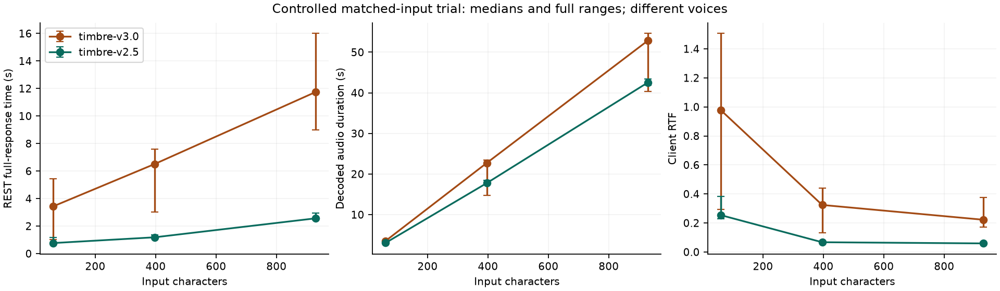

In [17]:
CONTROLLED = rows("results/report4/rest_latency_trials.csv")
assert len(CONTROLLED)==30
assert len({r["text_hash"] for r in CONTROLLED})==3
for r in CONTROLLED:
    assert abs(float(r["rtf_client"])-float(r["request_total_ms"])/1000/float(r["duration_s"]))<1e-10
show(S["report4"]["controlled_rest"])
show(CONTROLLED)
display(Image(filename=str(EVIDENCE/"results/report4/rest_duration_rtf.png")))

## 17. Separate warm WebSocket TTFA and extended buffering
**Method:** five warm short-prompt WS trials per model, excluding two cold socket warm-ups. TTFA ends at first playable PCM and is separate from full-file REST latency, semantic speech onset and any future-aware gap-free bound.
**Buffer tradeoff:** replay 32 saved traces at 0/50/100/200/500/1000 ms fixed startup buffers and 1/10/20 ms reporting tolerances = 576 conditions. Additional buffering reduces starvation but costs startup time. At 1000 ms, v3.0 still underruns in 2/3 earlier fresh SSE and 3/5 warm WS traces; v2.5 controls remain continuous. These are offline client-policy replays, not handset tests.

**Trace provenance:** 14 earlier N8 SSE + 6 later SSE + 10 measured warm WS + 2 cold WS warm-ups = 32. The two additional IDs are `R4-WARM-WS-3-1` and `R4-WARM-WS-25-1`. They enter offline buffer replay but are excluded from warm TTFA. Full inventory: `evidence/STREAMING_TRACE_PROVENANCE.md`. The two REST warm-ups are separate requests.

cohort,phase,trace_count
fresh_SSE,saved_trace,6
original_N8,saved_trace,14
report4_WS,cold_warmup,2
report4_WS,warm_measured,10


All 4 rows displayed; scroll the output for the complete table.


model,prompt_length,successful_trials,attempted_trials,ttfa_ms_median,ttfa_ms_min,ttfa_ms_max
timbre-v3.0,short,5,5,813.0,267.5,3015.5
timbre-v2.5,short,5,5,161.3,156.6,171.5


All 2 rows displayed; scroll the output for the complete table.


cohort,phase,case_id,request_id,model,voice,ok,connection,connect_ms,observed_ttfa_ms,request_total_ms,audio_duration_s,rtf_client,chunks,decoded_pcm_samples,audio_path,audio_sha256,timeline_path,timeline_sha256
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,Tarika,True,HTTP SSE,,3875.6,5316.3,1.68,3.1644642857142857,11,13440,results/next/audio/stream/N8-en-IN-short__timbre-v3.0-8000.wav,94f3ea12e09f76fb5f3bcfcad0dedf55f6ab621826e804ed136cb1ddb1ce8fc7,results/next/raw/tts_stream/N8-en-IN-short/timbre-v3.0-8000.json,6c5d89ab0aeeb488d3d4d7a3af1aa9a0ff047473ae965aec3fca861851566d54
original_N8,saved_trace,N8-en-IN-medium,N8-en-IN-medium-timbre-v3.0-24000-sse-5cb2b869,timbre-v3.0,Tarika,True,HTTP SSE,,3196.6,6380.7,6.64,0.960948795180723,125,159360,results/next/audio/stream/N8-en-IN-medium__timbre-v3.0-24000.wav,30f0a6b88b60e3bbd846d66c45c7829ec0455fb90500ba14115bfaee7e695838,results/next/raw/tts_stream/N8-en-IN-medium/timbre-v3.0-24000.json,d2eb5f426cc3d5c1f15db5a4848c5b7b2db8d5c0fb372de1d7ea0cd1b18b8034
original_N8,saved_trace,N8-en-IN-medium,N8-en-IN-medium-timbre-v3.0-8000-sse-50392c73,timbre-v3.0,Tarika,True,HTTP SSE,,1296.9,6615.0,7.2,0.91875,46,57600,results/next/audio/stream/N8-en-IN-medium__timbre-v3.0-8000.wav,75025fcc5fe05462f10277d9cd758163d35f89f9bb5f722b7ed0bdf43d0d3ce1,results/next/raw/tts_stream/N8-en-IN-medium/timbre-v3.0-8000.json,e5836d89a797f146f864100d9d0b6fbff28eb2574a657d2f470edaa96d24bb45
original_N8,saved_trace,N8-en-IN-long,N8-en-IN-long-timbre-v3.0-24000-sse-f4673eae,timbre-v3.0,Tarika,True,HTTP SSE,,590.3,10127.1,17.12,0.591536214953271,244,410880,results/next/audio/stream/N8-en-IN-long__timbre-v3.0-24000.wav,2f818fcde4e4497dd16fcc3b18e608b88f325f16c714ba46de0bdab46a659b83,results/next/raw/tts_stream/N8-en-IN-long/timbre-v3.0-24000.json,83cd3a890b550781890bf61be93cc9f736de94f7098912843ebcb0c01164337e
original_N8,saved_trace,N8-en-IN-long,N8-en-IN-long-timbre-v3.0-8000-sse-fb444baf,timbre-v3.0,Tarika,True,HTTP SSE,,1490.1,9205.3,17.76,0.5183164414414414,106,142080,results/next/audio/stream/N8-en-IN-long__timbre-v3.0-8000.wav,5b7ecc8035b2d2d95aa3ae925e2a7cef7adfb7e2a5e62342161f9c4b570933e3,results/next/raw/tts_stream/N8-en-IN-long/timbre-v3.0-8000.json,930286f7316797600a7abdf3ea91d8259da27a5c09d330b6775b81c030c8b524
original_N8,saved_trace,N8-hi-IN-short,N8-hi-IN-short-timbre-v3.0-24000-sse-9a7b7118,timbre-v3.0,Tarika,True,HTTP SSE,,2527.4,3576.1,2.24,1.596473214285714,35,53760,results/next/audio/stream/N8-hi-IN-short__timbre-v3.0-24000.wav,7c90e160c5a9e9666de782d9f2f535958fd5f9d1af24a388567eb8b13b7ad329,results/next/raw/tts_stream/N8-hi-IN-short/timbre-v3.0-24000.json,24d1f99474929a00d10b2181437a755e89f4775f3a0273c0cc0133c3b50f4451
original_N8,saved_trace,N8-hi-IN-short,N8-hi-IN-short-timbre-v3.0-8000-sse-453e65ec,timbre-v3.0,Tarika,True,HTTP SSE,,2001.2,3123.4,2.16,1.4460185185185186,15,17280,results/next/audio/stream/N8-hi-IN-short__timbre-v3.0-8000.wav,98da18913fd2665419108948bf6897e7e0fa9ea462b57029a3fb927d37acd009,results/next/raw/tts_stream/N8-hi-IN-short/timbre-v3.0-8000.json,96a36c105215e30b7c49bbac15d98763128bf415c372acdff26aca3f60c973f4
original_N8,saved_trace,N8-hi-IN-medium,N8-hi-IN-medium-timbre-v3.0-24000-sse-e4fbd5de,timbre-v3.0,Tarika,True,HTTP SSE,,2912.4,5830.5,5.76,1.0122395833333333,100,138240,results/next/audio/stream/N8-hi-IN-medium__timbre-v3.0-24000.wav,5cd542f04ac5542ef6a323174e5d674989d286df348f41356aa270fe354ee82e,results/next/raw/tts_stream/N8-hi-IN-medium/timbre-v3.0-24000.json,9f9c5aa1c3bc82efbc0f90c1c80eaa38ed80cd31f396d3c4d1f6998c00f93117
original_N8,saved_trace,N8-hi-IN-medium,N8-hi-IN-medium-timbre-v3.0-8000-sse-c2e0aa1f,timbre-v3.0,Tarika,True,HTTP SSE,,3056.6,6496.5,6.16,1.0546266233766233,44,49280,results/next/audio/stream/N8-hi-IN-medium__timbre-v3.0-8000.wav,f32fa64db152152768f9e4b9d2aeccf327cd9ceffda101cf323c2013e9b9557d,results/next/raw/tts_stream/N8-hi-IN-medium/timbre-v3.0-8000.json,7f776363d5afa4c066282000d3a28d3

All 32 rows displayed; scroll the output for the complete table.


... (2 outputs left out)

cohort,phase,case_id,request_id,model,initial_buffer_ms,tolerance_ms,observed_ttfa_ms,simulated_startup_ms,underflow_count,total_starvation_ms,retrospective_extra_wait_ms,retrospective_policy
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,0,1,3875.6,3875.625,1,1343.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,0,10,3875.6,3875.625,1,1343.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,0,20,3875.6,3875.625,1,1343.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,50,1,3875.6,3925.625,1,1293.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,50,10,3875.6,3925.625,1,1293.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,50,20,3875.6,3925.625,1,1293.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,100,1,3875.6,3975.625,1,1243.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,100,10,3875.6,3975.625,1,1243.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,100,20,3875.6,3975.625,1,1243.875,1343.875,"future-aware bound, not measured online TTFA"
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,200,1,3875.6,4075.6249999999995,1,1143.875,1343.875,"future-aware bound, not measured online TTFA"


All 576 rows displayed; scroll the output for the complete table.
All exact per-chunk rows: 4255


cohort,phase,case_id,request_id,model,chunk_index,arrival_s,arrival_sample,pcm_samples,sample_rate,chunk_duration_s,cumulative_received_audio_s,playable_buffer_before_s,playable_buffer_after_s,zero_buffer_starvation_s
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,0,3.8756,31005,490,8000,0.06125,0.06125,0.0,0.06125,0.0
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,1,5.2807,42246,1395,8000,0.174375,0.235625,0.0,0.174375,1.343875
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,2,5.2853,42282,2048,8000,0.256,0.491625,0.169875,0.425875,0.0
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,3,5.2854,42283,61,8000,0.007625,0.49925,0.42575,0.433375,0.0
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,4,5.3073,42458,1878,8000,0.23475,0.734,0.4115,0.64625,0.0
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,5,5.3076,42461,701,8000,0.087625,0.821625,0.645875,0.7335,0.0
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,6,5.3077,42462,694,8000,0.08675,0.908375,0.733375,0.820125,0.0
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,7,5.3152,42522,2048,8000,0.256,1.164375,0.812625,1.068625,0.0
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,8,5.3156,42525,2048,8000,0.256,1.420375,1.06825,1.32425,0.0
original_N8,saved_trace,N8-en-IN-short,N8-en-IN-short-timbre-v3.0-8000-sse-999000ec,timbre-v3.0,9,5.3158,42526,829,8000,0.103625,1.524,1.324125,1.42775,0.0


All 4255 rows displayed; scroll the output for the complete table.


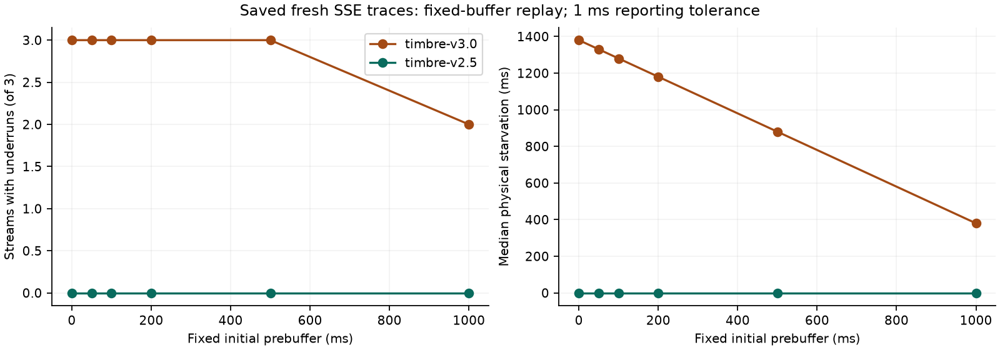

In [18]:
trace_rows=rows("results/report4/stream_trials.csv")
trace_counts=pd.DataFrame(trace_rows).groupby(["cohort","phase"]).size().reset_index(name="trace_count")
show(trace_counts)
assert len(trace_rows)==32 and len({r["request_id"] for r in trace_rows})==32
assert {r["case_id"] for r in trace_rows if r["phase"]=="cold_warmup"}=={"R4-WARM-WS-3-1","R4-WARM-WS-25-1"}
show(S["report4"]["streaming"]["warm_ws"])
show(rows("results/report4/stream_trials.csv"))
show(rows("results/report4/buffer_summary.csv"))
buffer_rows=rows("results/report4/buffer_sensitivity.csv")
assert len(buffer_rows)==576
show(buffer_rows)
chunks=rows("results/report4/stream_chunk_timeline.csv")
print("All exact per-chunk rows:",len(chunks))
show(chunks)
display(Image(filename=str(EVIDENCE/"results/report4/buffer_tradeoff.png")))

## 18. Disjoint HTTP outcomes, retries and empty PCM
**Earlier functionality cohort:** 73 cases / 74 HTTP attempts, including six SSE HTTP requests. Disjoint outcomes: 66 valid PCM, six empty PCM, one recovered HTTP 500 and one expected tag-only HTTP 400. One retry is separate from eight explicitly named rechecks.
**Rates:** 66/74 valid-attempt success differs from 66/73 eventual case success; excluding the expected negative case gives 66/72 positive-case success. These enriched diagnostic cohorts are not production reliability samples.
**Controlled collection:** 32 REST requests include 30 measured and two warm-ups; its 12 WebSocket requests are tracked separately. New listening/rewrites have 54 REST cases, 53 valid and one additional empty v3.0 response. Saved SSE WAV bytes are not falsely presented as original wire-body byte counts.

In [19]:
show([{"cohort":k,**v} for k,v in S["report4"]["http_cohorts"].items()])
HTTP=rows("results/report4/tts_http_attempts.csv")
assert len({r["attempt_id"] for r in HTTP})==len(HTTP)
show(HTTP)
show([r for r in HTTP if r["attempt_outcome"]!="valid_pcm"])

cohort,cases,http_attempts,valid_pcm_attempts,disjoint_attempt_outcomes,http_status_counts,eventual_success_cases,attempt_success_rate,eventual_case_success_rate,positive_case_success_rate,expected_rejections,retry_attempts,explicit_recheck_cases,final_case_outcomes
timbre_followup,73,74,66,"{'valid_pcm': 66, 'empty_pcm': 6, 'http_error': 2}","{'200': 72, '500': 1, '400': 1}",66,0.891892,0.904110,0.916667,1,1,8,"{'success': 65, 'persistent_empty': 6, 'recovered_on_retry': 1, 'expected_rejection': 1}"
report4_controlled,32,32,32,{'valid_pcm': 32},{'200': 32},32,1.000000,1.000000,1.000000,0,0,0,{'success': 32}
report4_quality,54,54,53,"{'valid_pcm': 53, 'empty_pcm': 1}",{'200': 54},53,0.981481,0.981481,0.981481,0,0,0,"{'success': 53, 'persistent_empty': 1}"


All 3 rows displayed; scroll the output for the complete table.


cohort,phase,case_id,attempt_id,retry_of,recheck_of,version,voice_id,input_text,input_chars,input_words,text_hash,request_fingerprint,endpoint,language,speed,sample_rate,encoding,container,http_status,error_code,error_code_origin,error_detail,transport,body_bytes,saved_audio_bytes,body_representation,body_path,body_sha256,decoded_pcm_samples,decoded_frames,duration_s,decoded_sample_rate,latency_ms,request_total_ms,rtf_client,retry_backoff_ms,scheduled_retry_backoff_ms,retry_inclusive_ms,attempt_number,attempt_outcome,expected_http,started_at,region,first_byte_ms,channels,sample_width,final_case_outcome,case_attempts,retries
timbre_followup,initial_followup,NF-R-3-short-1,NF-R-3-short-1-run1-a1-db9dacc0,,,timbre-v3.0,Tarika,Your request has been received. We will contact you tomorrow.,61,10,d6e7260b8a666374b631a3b5c290285c3d61da539ae5d377a12cfb8e0bebed87,722848c7244e811a16915b2c,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,,client classification; provider-specific code unavailable when absent,,REST,188204,188204,original HTTP response body,results/timbre_followup/audio/NF-R-3-short-1-run1-a1-db9dacc0.wav,4fd8db6780143278f8ea40f88160f7eb64c4d030790bbe490a27b56e1f413aa7,94080,94080,3.92,24000,4195.2,4195.2,1.070204081632653,0,0,4195.3,1,valid_pcm,200,2026-11-15T07:48:56.787+00:00,not supplied by recorded API metadata,not collected,1,2,success,1,0
timbre_followup,initial_followup,NF-R-25-short-1,NF-R-25-short-1-run1-a1-cf9b80a0,,,timbre-v2.5,Kaveri,Your request has been received. We will contact you tomorrow.,61,10,d6e7260b8a666374b631a3b5c290285c3d61da539ae5d377a12cfb8e0bebed87,ed467025ba063fa123e4c371,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,,client classification; provider-specific code unavailable when absent,,REST,130604,130604,original HTTP response body,results/timbre_followup/audio/NF-R-25-short-1-run1-a1-cf9b80a0.wav,729b5589f064d0907a45eed6ab22553de079687392e6ee8ea07cc059e5e85b91,65280,65280,2.72,24000,713.7,713.7,0.26238970588235294,0,0,713.7,1,valid_pcm,200,2026-11-15T07:49:01.171+00:00,not supplied by recorded API metadata,not collected,1,2,success,1,0
timbre_followup,initial_followup,NF-R-3-short-2,NF-R-3-short-2-run1-a1-ade02bfa,,,timbre-v3.0,Tarika,Your request has been received. We will contact you tomorrow.,61,10,d6e7260b8a666374b631a3b5c290285c3d61da539ae5d377a12cfb8e0bebed87,722848c7244e811a16915b2c,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,,client classification; provider-specific code unavailable when absent,,REST,169004,169004,original HTTP response body,results/timbre_followup/audio/NF-R-3-short-2-run1-a1-ade02bfa.wav,4b44c6988f94415f83351f4c43d9a6815f03eb855a8d79769e59e313a71efaa9,84480,84480,3.52,24000,5279.2,5279.2,1.499772727272727,0,0,5279.3,1,valid_pcm,200,2026-11-15T07:49:52.320+00:00,not supplied by recorded API metadata,not collected,1,2,success,1,0
timbre_followup,initial_followup,NF-R-25-short-2,NF-R-25-short-2-run1-a1-efb1e466,,,timbre-v2.5,Kaveri,Your request has been received. We will contact you tomorrow.,61,10,d6e7260b8a666374b631a3b5c290285c3d61da539ae5d377a12cfb8e0bebed87,ed467025ba063fa123e4c371,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,,client classification; provider-specific code unavailable when absent,,REST,145964,145964,original HTTP response body,results/timbre_followup/audio/NF-R-25-short-2-run1-a1-efb1e466.wav,b1a51c6a57cda9072f80a6b4f6d996dc69aa70d1e7b5574617a1f7fae324c4bb,72960,72960,3.04,24000,541.6,541.6,0.1781578947368421,0,0,541.7,1,valid_pcm,200,2026-11-15T07:49:57.779+00:00,not supplied by recorded API metadata,not collected,1,2,success,1,0
timbre_followup,initial_followup,NF-R-3-short-3,NF-R-3-short-3-run1-a1-f21334c7,,,timbre-v3.0,Tarika,Your request has been received. We will contact you tomorrow.,61,10,d6e7260b8a666374b631a3b5c290285c3d61da539ae5d377a12cfb8e0bebed87,722848c7244e811a16915b2c,https://api.vachana.ai/api/v1/tts/

All 160 rows displayed; scroll the output for the complete table.


cohort,phase,case_id,attempt_id,retry_of,recheck_of,version,voice_id,input_text,input_chars,input_words,text_hash,request_fingerprint,endpoint,language,speed,sample_rate,encoding,container,http_status,error_code,error_code_origin,error_detail,transport,body_bytes,saved_audio_bytes,body_representation,body_path,body_sha256,decoded_pcm_samples,decoded_frames,duration_s,decoded_sample_rate,latency_ms,request_total_ms,rtf_client,retry_backoff_ms,scheduled_retry_backoff_ms,retry_inclusive_ms,attempt_number,attempt_outcome,expected_http,started_at,region,first_byte_ms,channels,sample_width,final_case_outcome,case_attempts,retries
timbre_followup,initial_followup,NF-T-3-en-sigh,NF-T-3-en-sigh-run1-a1-6dd3bd6f,,,timbre-v3.0,Tarika,Your request is ready. <sigh> Please continue when you are ready.,65,11,a006ff2e202d672365f7559e2ac8366f7beed0fe7d98cda0baaaf105581844ad,6a76c16ace03a80679144bd3,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,EMPTY_PCM,client classification; provider-specific code unavailable when absent,empty or silent audio,REST,44,44,original HTTP response body,results/timbre_followup/audio/NF-T-3-en-sigh-run1-a1-6dd3bd6f.wav,3b234823dbcc419fe5f4e95309cb64cbd883fd45f7fd26c1dce5371485770328,0,0,0.0,24000,5120.1,5120.1,,0,0,5120.2,1,empty_pcm,200,2026-11-15T07:52:21.921+00:00,not supplied by recorded API metadata,not collected,1,2,persistent_empty,1,0
timbre_followup,initial_followup,NF-T-3-en-yawns,NF-T-3-en-yawns-run1-a1-fbc66b65,,,timbre-v3.0,Tarika,Your request is ready. <yawns> Please continue when you are ready.,66,11,f6a3b828427965e5e9cd5bd613bb4d07a5d618fb1d478931e14ec372b09f2a92,dfa746045a56e0d109ef7968,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,EMPTY_PCM,client classification; provider-specific code unavailable when absent,empty or silent audio,REST,44,44,original HTTP response body,results/timbre_followup/audio/NF-T-3-en-yawns-run1-a1-fbc66b65.wav,3b234823dbcc419fe5f4e95309cb64cbd883fd45f7fd26c1dce5371485770328,0,0,0.0,24000,5132.6,5132.6,,0,0,5132.7,1,empty_pcm,200,2026-11-15T07:52:34.730+00:00,not supplied by recorded API metadata,not collected,1,2,persistent_empty,1,0
timbre_followup,initial_followup,NF-V-3-0_85,NF-V-3-0_85-run1-a1-328f6b73,,,timbre-v3.0,Tarika,Your request is ready. Please continue when you are ready.,58,10,9afba2692c3974a2037cbca2899147ab980b53c327b4506cc60568cec07b2957,7c061669729798822b0e5e71,https://api.vachana.ai/api/v1/tts/inference,en-IN,0.85,24000,linear_pcm,wav,500,HTTP_500,client classification; provider-specific code unavailable when absent,"{""success"": false, ""message"": ""We are facing technical difficulties. Please try again later."", ""status_code"": 500}",REST,109,,original HTTP response body,results/timbre_followup/raw/tts/NF-V-3-0_85/NF-V-3-0_85-run1-a1-328f6b73.json,832dd8d3b3073d46801abca275dbb12dd4cb25e212cac672489b886ca1197456,0,0,0.0,24000,85.0,85.0,,0,0,85.1,1,http_error,200,2026-11-15T07:53:24.641+00:00,not supplied by recorded API metadata,not collected,1,2,recovered_on_retry,2,1
timbre_followup,initial_followup,NF-C-3-raw,NF-C-3-raw-run1-a1-72d4d732,,,timbre-v3.0,Tarika,The change was -2.5 percent. The PIN is 0070. The call starts at 9:05 AM.,73,15,22ad0be1ae2bcc6fd0099a78f187bc2cb9a37dbd8adf5da33d1950e8d7b3fab2,7c9903f6d25467f6ef70308b,https://api.vachana.ai/api/v1/tts/inference,en-IN,1.0,24000,linear_pcm,wav,200,EMPTY_PCM,client classification; provider-specific code unavailable when absent,empty or silent audio,REST,44,44,original HTTP response body,results/timbre_followup/audio/NF-C-3-raw-run1-a1-72d4d732.wav,3b234823dbcc419fe5f4e95309cb64cbd883fd45f7fd26c1dce5371485770328,0,0,0.0,24000,5092.8,5092.8,,0,0,5092.9,1,empty_pcm,200,2026-11-15T07:53:46.482+00:00,not supplied by recorded API metadata,not collected,1,2,persistent_empty,1,0
timbre_followup,initial_followup,NF-N-3-hi,NF-N-3-hi-run1-a1-0e2788ef,,,timbre-v3.0,Shivani,आपका अनुरोध तैयार है। जब आप तैयार हों तो कृपया आगे बढ़ें।,57,12,c182a0

All 9 rows displayed; scroll the output for the complete table.


## 19. Concurrency, short soak and cleanup regressions
**Method:** first-round request parallelism 1/2/4/8 is separated from retries/backoff. A ten-minute low-rate soak alternates ASR/TTS requests. Request concurrency is not simultaneous telephone-call capacity.
**Output:** per-round results and request-level diagnostics. At eight simultaneous requests: ASR 8/8 with six retried; TTS 2/8 after retries. Short soak: 30/30. Cancellation/socket-cleanup unit tests are implementation fixtures, not live telephone evidence.

In [20]:
show(S["request_diagnostics"]["concurrency"])
print("Low-rate ten-minute soak:",S["request_diagnostics"]["soak"])
print("Historical public-attempt reliability:",S["request_diagnostics"]["baseline_reliability"])
show(rows("results/submission/request_attempts.csv"))

kind,requested_parallelism,max_http_attempts_inflight,attempt_rows,http_429_attempts,completed_requests,successful_requests,retried_requests,definition
asr,1,1,1,0,1,1,0,first experiment round only; client dispatch-to-full-body intervals; excludes backoff; no provider queue visibility
asr,2,2,2,0,2,2,0,first experiment round only; client dispatch-to-full-body intervals; excludes backoff; no provider queue visibility
asr,4,4,6,2,4,4,2,first experiment round only; client dispatch-to-full-body intervals; excludes backoff; no provider queue visibility
asr,8,8,20,12,8,8,6,first experiment round only; client dispatch-to-full-body intervals; excludes backoff; no provider queue visibility
tts,1,1,1,0,1,1,0,first experiment round only; client dispatch-to-full-body intervals; excludes backoff; no provider queue visibility
tts,2,2,4,2,2,2,1,first experiment round only; client dispatch-to-full-body intervals; excludes backoff; no provider queue visibility
tts,4,4,10,6,4,4,3,first experiment round only; client dispatch-to-full-body intervals; excludes backoff; no provider queue visibility
tts,8,8,29,27,8,2,7,first experiment round only; client dispatch-to-full-body intervals; excludes backoff; no provider queue visibility


All 8 rows displayed; scroll the output for the complete table.
Low-rate ten-minute soak: {'requests': 30, 'successes': 30}
Historical public-attempt reliability: {'asr': {'attempts': 243, 'failed_attempts': 0}, 'tts': {'attempts': 213, 'failed_attempts': 4}, 'tts_stream': {'attempts': 63, 'failed_attempts': 0}, 'tts_ws': {'attempts': 28, 'failed_attempts': 1}}


log,kind,case_id,run_tag,request_id,server_request_id,started_at_utc,http_status,success,attempt,retry_count,latency_ms,retry_inclusive_ms,error,model,voice,request_settings,raw_path,timeline_path
results/attempts.jsonl,asr,CL-EN-01,pilot,CL-EN-01-pilot-a1-c00ce2cb,,2026-11-13T16:20:53.905+00:00,200,True,1,0,548.0,548.1,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""en-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/CL-EN-01/pilot_a1.json,
results/attempts.jsonl,tts,T31,pilot,T31-pilot-a1-7c6faa20,,2026-11-13T16:20:54.460+00:00,200,True,1,0,1937.3,1937.3,,timbre-v3.0,Tarika,"{""audio_config"": {""container"": ""wav"", ""encoding"": ""linear_pcm"", ""num_channels"": 1, ""sample_rate"": 24000, ""sample_width"": 2}, ""endpoint"": ""https://api.vachana.ai/api/v1/tts/inference"", ""language"": ""en-IN"", ""model"": ""timbre-v3.0"", ""speed"": 1.0, ""voice"": ""Tarika""}",results/raw/tts/T31/pilot_a1.bin,
results/attempts.jsonl,asr,CL-EN-02,run1,CL-EN-02-run1-a1-caf2aba9,,2026-11-13T16:52:04.620+00:00,200,True,1,0,589.8,589.9,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""en-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/CL-EN-02/run1_a1.json,
results/attempts.jsonl,asr,CL-HI-01,run1,CL-HI-01-run1-a1-0abbd4df,,2026-11-13T16:52:05.220+00:00,200,True,1,0,188.0,188.2,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""hi-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/CL-HI-01/run1_a1.json,
results/attempts.jsonl,asr,CL-TE-01,run1,CL-TE-01-run1-a1-a17fb5fa,,2026-11-13T16:52:05.416+00:00,200,True,1,0,201.6,201.7,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""te-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/CL-TE-01/run1_a1.json,
results/attempts.jsonl,asr,NUM-EN-01,run1,NUM-EN-01-run1-a1-d288c6dc,,2026-11-13T16:52:05.626+00:00,200,True,1,0,191.9,192.0,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""en-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/NUM-EN-01/run1_a1.json,
results/attempts.jsonl,asr,SNR-EN-00,run1,SNR-EN-00-run1-a1-f73e6690,,2026-11-13T16:52:05.825+00:00,200,True,1,0,132.1,132.2,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""en-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/SNR-EN-00/run1_a1.json,
results/attempts.jsonl,asr,TEL-HI-ALAW,run1,TEL-HI-ALAW-run1-a1-8fd51199,,2026-11-13T16:52:05.964+00:00,200,True,1,0,132.3,132.4,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""hi-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/TEL-HI-ALAW/run1_a1.json,
results/attempts.jsonl,asr,RN-EN-01,run1,RN-EN-01-run1-a1-0a086e5b,,2026-11-13T16:52:06.105+00:00,200,True,1,0,198.9,199.0,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""en-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/RN-EN-01/run1_a1.json,
results/attempts.jsonl,asr,PAUSE-EN-01,run1,PAUSE-EN-01-run1-a1-b18b7988,,2026-11-13T16:52:06.312+00:00,200,True,1,0,219.3,219.4,,prisma-v3.0,,"{""endpoint"": ""https://api.vachana.ai/stt/v3"", ""format"": ""transcribe"", ""language_code"": ""en-IN"", ""model"": ""prisma-v3.0""}",results/raw/asr/PAUSE-EN-01/run1_a1.json,


All 1285 rows displayed; scroll the output for the complete table.


## 20. Human raw/rewrite mitigation pairs and held-out preparation
**Historical scored sample:** nine complete human pairs: eight fixed and one wrong in both variants. These were selected from suspected failures and do not establish population rewrite effectiveness.
**Held-out material:** frozen rules produced ten new English v2.5/Kaveri raw/rewrite pairs covering signs, currency, zeros, dates, times and negation. All 20 outputs exist; human correctness marks remain blank. Do not assign fixed/newly broken/both-correct/both-wrong until real marks arrive.

In [21]:
show(rows("results/submission/tts_human_rewrite_pairs.csv"))
show(rows("results/report4_quality/tts_rewrite_pairs.csv"))
show(rows("data/report4/tts_rewrite_manifest.csv"))
example=D["rewrites"][0]
for side in ["before","after"]:
    r=registry[example[side]];display(Markdown("**"+r["id"]+"** — "+r.get("prompt","")));display(Audio(filename=str(ROOT/r["audio"]),embed=True))

pair_id,raw_case_id,rewritten_case_id,raw_correct,rewritten_correct,outcome
en-sign-inr,NT018,NT020,False,True,fixed
en-sign-pct,NT015,NT017,False,True,fixed
en-time-905,NT027,NT028,False,True,fixed
hi-ident,NT035,NT036,False,True,fixed
hi-signed,NT033,NT034,False,True,fixed
mix-close,NT065,NT066,False,False,both_failed
mix-sign,NT063,NT064,False,True,fixed
te-ident,NT043,NT044,False,True,fixed
te-signed,NT041,NT042,False,True,fixed


All 9 rows displayed; scroll the output for the complete table.


pair_id,category,language,model,expected_meaning,raw_case_id,rewrite_case_id,raw_audio_path,rewrite_audio_path,listener_id,raw_correct,rewrite_correct,outcome,notes
R4-N-01,negative,en-IN,timbre-v2.5,minus 3.75 percent,R4-N-01-raw,R4-N-01-rewrite,results/report4_quality/listen/R4-N-01-raw.wav,results/report4_quality/listen/R4-N-01-rewrite.wav,,,,,
R4-N-02,currency,en-IN,timbre-v2.5,24680 rupees and 50 paise,R4-N-02-raw,R4-N-02-rewrite,results/report4_quality/listen/R4-N-02-raw.wav,results/report4_quality/listen/R4-N-02-rewrite.wav,,,,,
R4-N-03,identifier,en-IN,timbre-v2.5,0 0 4 8 in order,R4-N-03-raw,R4-N-03-rewrite,results/report4_quality/listen/R4-N-03-raw.wav,results/report4_quality/listen/R4-N-03-rewrite.wav,,,,,
R4-N-04,identifier,en-IN,timbre-v2.5,0 0 1 0 2 6 in order,R4-N-04-raw,R4-N-04-rewrite,results/report4_quality/listen/R4-N-04-raw.wav,results/report4_quality/listen/R4-N-04-rewrite.wav,,,,,
R4-N-05,date,en-IN,timbre-v2.5,17 April 2027,R4-N-05-raw,R4-N-05-rewrite,results/report4_quality/listen/R4-N-05-raw.wav,results/report4_quality/listen/R4-N-05-rewrite.wav,,,,,
R4-N-06,time,en-IN,timbre-v2.5,09:07 AM,R4-N-06-raw,R4-N-06-rewrite,results/report4_quality/listen/R4-N-06-raw.wav,results/report4_quality/listen/R4-N-06-rewrite.wav,,,,,
R4-N-07,time,en-IN,timbre-v2.5,12:05 PM,R4-N-07-raw,R4-N-07-rewrite,results/report4_quality/listen/R4-N-07-raw.wav,results/report4_quality/listen/R4-N-07-rewrite.wav,,,,,
R4-N-08,currency,en-IN,timbre-v2.5,8240 rupees,R4-N-08-raw,R4-N-08-rewrite,results/report4_quality/listen/R4-N-08-raw.wav,results/report4_quality/listen/R4-N-08-rewrite.wav,,,,,
R4-N-09,negation,en-IN,timbre-v2.5,buy 12; prohibit buying 21,R4-N-09-raw,R4-N-09-rewrite,results/report4_quality/listen/R4-N-09-raw.wav,results/report4_quality/listen/R4-N-09-rewrite.wav,,,,,
R4-N-10,negation,en-IN,timbre-v2.5,prohibit transfer 950; retain 1250,R4-N-10-raw,R4-N-10-rewrite,results/report4_quality/listen/R4-N-10-raw.wav,results/report4_quality/listen/R4-N-10-rewrite.wav,,,,,


All 10 rows displayed; scroll the output for the complete table.


case_id,pair_id,category,variant,text,text_sha256,language,model,voice,expected_meaning,score_status
R4-N-01-raw,R4-N-01,negative,raw,The return was -3.75 percent.,137fae829ba86370fa485bf361711508216845ce778be6b5f35fe2a5795a967b,en-IN,timbre-v2.5,Kaveri,minus 3.75 percent,awaiting_new_human_listening
R4-N-01-rewrite,R4-N-01,negative,rewrite,The return was minus three point seven five percent.,6a4c2d11b7c4aec7ce8aca0f5abfadffda81267c42807437e0058e1b6a2e176b,en-IN,timbre-v2.5,Kaveri,minus 3.75 percent,awaiting_new_human_listening
R4-N-02-raw,R4-N-02,currency,raw,"The balance is ₹24,680.50.",13eb437511533f8b3c892d178f1718db1acaca6f3d1bbae96044d9ae9b075bb1,en-IN,timbre-v2.5,Kaveri,24680 rupees and 50 paise,awaiting_new_human_listening
R4-N-02-rewrite,R4-N-02,currency,rewrite,The balance is twenty four thousand six hundred eighty rupees and fifty paise.,2842eb0b55a0cc1927a59083413799f1066a27e006389047acfce129f8281c93,en-IN,timbre-v2.5,Kaveri,24680 rupees and 50 paise,awaiting_new_human_listening
R4-N-03-raw,R4-N-03,identifier,raw,Your PIN is 0048.,34877fafbe796d302720dd70dd6368e2b6e5ef20e4eee7142946d1f964c5f52d,en-IN,timbre-v2.5,Kaveri,0 0 4 8 in order,awaiting_new_human_listening
R4-N-03-rewrite,R4-N-03,identifier,rewrite,Your PIN is zero zero four eight.,2502b89a7f33225dfe7380b232c4094398b3a3628a6c2ec67053798b73f46f28,en-IN,timbre-v2.5,Kaveri,0 0 4 8 in order,awaiting_new_human_listening
R4-N-04-raw,R4-N-04,identifier,raw,Your reference number is 001026.,eae994e260babd3ca06cd3d54eb94332f0b11203b78587c1bee0f2295d90a544,en-IN,timbre-v2.5,Kaveri,0 0 1 0 2 6 in order,awaiting_new_human_listening
R4-N-04-rewrite,R4-N-04,identifier,rewrite,Your reference number is zero zero one zero two six.,62e7cf6d710ba2ce2ef0cec1a7cf8f2cf94e0d00a983d4f240bb2c212f621368,en-IN,timbre-v2.5,Kaveri,0 0 1 0 2 6 in order,awaiting_new_human_listening
R4-N-05-raw,R4-N-05,date,raw,The payment date is 17/04/2027.,001246ddd7fcb3120cd4e6e4d7e2bf4b83ad1451c00ffc6477efc2d668f59a4f,en-IN,timbre-v2.5,Kaveri,17 April 2027,awaiting_new_human_listening
R4-N-05-rewrite,R4-N-05,date,rewrite,"The payment date is the seventeenth of April, twenty twenty seven.",6a3c7caf0fc0c2a2c197b857717b2e244e67b80b9ca53347ae265300e9be7473,en-IN,timbre-v2.5,Kaveri,17 April 2027,awaiting_new_human_listening


All 20 rows displayed; scroll the output for the complete table.


**NT018** — Your balance is −₹3,200.

**NT020** — Your balance is minus three thousand two hundred rupees.

## 21. Frozen-vocabulary held-out ASR check
**Method:** generic financial vocabulary was frozen before selecting fresh source audio or observing new predictions. The old SVQ inventory had too few unused clean domain utterances; the unchanged vocabulary was tested on 15 new public MInDS-14 banking recordings. Each recording receives baseline and hinted Prisma v3.0 requests in the same output mode; conditions are interleaved.
**Result:** 29/150 → 28/150 word edits, WER 19.33% → 18.67%; one improved, 14 unchanged, none regressed. Frozen target-word recall changes 14/15 → 15/15, with no absent-reference hinted-word insertion flags.
**Critical limit:** every represented target occurrence is “account.” This does not establish bank-name/acronym gains. Source speech is 8 kHz US English with unknown speaker identities, and original dataset labels are not independently human verified. Lexical slot checks are not complete semantic transaction correctness. The 15 recordings remain outside primary baseline WER.

In [22]:
H=S["report4_heldout"]
show([{"condition":k,**v} for k,v in H["asr"].items()])
print("Paired outcomes:",H["paired_outcomes"],"Target coverage:",H["target_term_coverage"])
show(rows("data/report4/asr_heldout_manifest.csv"))
show(rows("results/report4_quality/asr_heldout_keyterm_results.csv"))
show(rows("results/report4_quality/asr_heldout_pairs.csv"))

condition,speech_clips,reference_words,word_edits,wer,cer,cer_no_spaces,target_terms_correct,target_terms_total,target_set_exact_clips,critical_lexical_slots_correct_clips,hinted_vocabulary_insertion_flags
baseline,15,150,29,0.193333,0.158273,0.151786,14,15,14,14,0
hinted,15,150,28,0.186667,0.152518,0.146429,15,15,15,15,0


All 2 rows displayed; scroll the output for the complete table.
Paired outcomes: {'unchanged': 14, 'improved': 1} Target coverage: {'account': 15}


clip_id,input_path,input_sha256,language,source_locale,duration_s,sample_rate_hz,source_dataset,source_revision,source_ref,source_row_index,speaker_id,reference_transcript,reference_basis,license,target_terms_json,frozen_vocabulary_sha256,status
R4-ASR-01,data/report4/audio/R4-ASR-01.wav,8b6bd943c30de54d225d0dade582e74c6818e000ccec15bcc065437594036d1d,en-IN,en-US,5.12,8000,PolyAI/minds14,40ce77cb32a384e4d50a568e1ec39ac804019d33,en-US~BALANCE/602ba418bb1e6d0fbce92030.wav,70,not supplied,so you spent the money I'd like to see my new account balance,original dataset transcription; not independently human verified,CC-BY-4.0,"[""account""]",ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,prepared_not_run
R4-ASR-02,data/report4/audio/R4-ASR-02.wav,aff56125337ca50475f094c8b27eb0ada067082787c10ed508368b2a8b6d10b4,en-IN,en-US,4.778625,8000,PolyAI/minds14,40ce77cb32a384e4d50a568e1ec39ac804019d33,en-US~JOINT_ACCOUNT/602ba6b8963e11ccd901ccda.wav,38,not supplied,add someone to my account please,original dataset transcription; not independently human verified,CC-BY-4.0,"[""account""]",ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,prepared_not_run
R4-ASR-03,data/report4/audio/R4-ASR-03.wav,ac81859e49c3413b00d6955f90a73bd5d69248ad402afb4037153ff52ffbdfe6,en-IN,en-US,6.570625,8000,PolyAI/minds14,40ce77cb32a384e4d50a568e1ec39ac804019d33,en-US~JOINT_ACCOUNT/602b9a59bb1e6d0fbce91f51.wav,35,not supplied,hello I was just calling to see if I can make it a joint account with my wife thank you,original dataset transcription; not independently human verified,CC-BY-4.0,"[""account""]",ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,prepared_not_run
R4-ASR-04,data/report4/audio/R4-ASR-04.wav,e00ade705e9af6ea1cc927b98ef06aaacbe012463d2e799b831ac65b37557ec0,en-IN,en-US,2.730625,8000,PolyAI/minds14,40ce77cb32a384e4d50a568e1ec39ac804019d33,en-US~BALANCE/602baa3abb1e6d0fbce9215b.wav,77,not supplied,show me my account balance please,original dataset transcription; not independently human verified,CC-BY-4.0,"[""account""]",ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,prepared_not_run
R4-ASR-05,data/report4/audio/R4-ASR-05.wav,20d6a084401ef13b3fe6de4484c4d9da2b9000a691535d2c58d719689387c666,en-IN,en-US,10.837375,8000,PolyAI/minds14,40ce77cb32a384e4d50a568e1ec39ac804019d33,en-US~JOINT_ACCOUNT/602ba55abb1e6d0fbce92065.wav,0,not supplied,I would like to set up a joint account with my partner,original dataset transcription; not independently human verified,CC-BY-4.0,"[""account""]",ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,prepared_not_run
R4-ASR-06,data/report4/audio/R4-ASR-06.wav,448b79825ff42a8761339a48b7ea890b9bf7375f9f61c4d4a48542414de63114,en-IN,en-US,3.84,8000,PolyAI/minds14,40ce77cb32a384e4d50a568e1ec39ac804019d33,en-US~JOINT_ACCOUNT/602bae9fbb1e6d0fbce92278.wav,36,not supplied,how do I set up a joint account,original dataset transcription; not independently human verified,CC-BY-4.0,"[""account""]",ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,prepared_not_run
R4-ASR-07,data/report4/audio/R4-ASR-07.wav,42cb359928384f9b2eb4111f0ff6de3e24d787bdefda374c082ac2125168278d,en-IN,en-US,5.479875,8000,PolyAI/minds14,40ce77cb32a384e4d50a568e1ec39ac804019d33,en-US~JOINT_ACCOUNT/602ba63d05f96973d679444d.wav,22,not supplied,how can my wife and I set up a joint account,original dataset transcription; not independently human verified,CC-BY-4.0,"[""account""]",ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,prepared_not_run
R4-ASR-08,data/report4/audio/R4-ASR-08.wav,51a7ba8c4d389585b84958ec677770058bdb9d7f12c3055652e99d62fe8066c5,en-IN,en-US,4.864,8000,PolyAI/minds14,40ce77cb32a384e4d50a568e1ec39ac804019d33,en-US~JOINT_ACCOUNT/602b9b6705f96973d67943ca.wav,15,not supplied,I was hoping to set up a joint account,original dataset transcription; not independently human verified,CC-BY-4.0,"[""account""]",ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905

All 15 rows displayed; scroll the output for the complete table.


clip_id,condition,reference,hypothesis,reference_normalized,hypothesis_normalized,ref_word_count,word_edits,ref_char_count,char_edits,nospace_ref_chars,nospace_char_edits,substitutions,deletions,insertions,wer,cer,false_transcription,no_speech_inserted_words,target_terms_json,target_terms_correct,target_terms_total,target_set_exact,numeric_string_sequence_match,negative_marker_match,critical_lexical_slots_correct,hinted_vocabulary_insertion_flags_json,hinted_vocabulary_insertion_flags,request_id,latency_ms,input_path,input_sha256,response_path,response_sha256,policy_sha256,source_dataset,source_ref,source_locale
R4-ASR-01,baseline,so you spent the money I'd like to see my new account balance,So I just spent some money. I'd like to see my new account balance,so you spent the money i d like to see my new account balance,so i just spent some money i d like to see my new account balance,14,3,61,8,48,7,2,0,1,0.21428571428571427,0.13114754098360656,,,"[""account""]",1,1,True,True,True,True,[],0,R4-ASR-01-baseline-report4_heldout-a1-5e2f3023,209.2,data/report4/audio/R4-ASR-01.wav,8b6bd943c30de54d225d0dade582e74c6818e000ccec15bcc065437594036d1d,results/report4_quality/raw/asr/R4-ASR-01-baseline/R4-ASR-01-baseline-report4_heldout-a1-5e2f3023.json,48d9cda9924065e633600d3e0a8331ec53eae03ee5f7805c28b971de2192e8e6,ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,PolyAI/minds14,en-US~BALANCE/602ba418bb1e6d0fbce92030.wav,en-US
R4-ASR-01,hinted,so you spent the money I'd like to see my new account balance,So I just spent some money. I'd like to see my new account balance.,so you spent the money i d like to see my new account balance,so i just spent some money i d like to see my new account balance,14,3,61,8,48,7,2,0,1,0.21428571428571427,0.13114754098360656,,,"[""account""]",1,1,True,True,True,True,[],0,R4-ASR-01-hinted-report4_heldout-a1-18d0714d,274.1,data/report4/audio/R4-ASR-01.wav,8b6bd943c30de54d225d0dade582e74c6818e000ccec15bcc065437594036d1d,results/report4_quality/raw/asr/R4-ASR-01-hinted/R4-ASR-01-hinted-report4_heldout-a1-18d0714d.json,8a77d023b65462975cf78dfd6c30ecb176c5dfa9a08876ad245af688d3677238,ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,PolyAI/minds14,en-US~BALANCE/602ba418bb1e6d0fbce92030.wav,en-US
R4-ASR-02,baseline,add someone to my account please,I'd like to add someone to my account please,add someone to my account please,i d like to add someone to my account please,6,4,32,12,27,8,0,0,4,0.6666666666666666,0.375,,,"[""account""]",1,1,True,True,True,True,[],0,R4-ASR-02-baseline-report4_heldout-a1-00513094,174.5,data/report4/audio/R4-ASR-02.wav,aff56125337ca50475f094c8b27eb0ada067082787c10ed508368b2a8b6d10b4,results/report4_quality/raw/asr/R4-ASR-02-baseline/R4-ASR-02-baseline-report4_heldout-a1-00513094.json,a6b905390aa42424e698ce54d851bdeb070e858a2001ac7a22b9d2f4b6cef49c,ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,PolyAI/minds14,en-US~JOINT_ACCOUNT/602ba6b8963e11ccd901ccda.wav,en-US
R4-ASR-02,hinted,add someone to my account please,"I'd like to add someone to my account, please.",add someone to my account please,i d like to add someone to my account please,6,4,32,12,27,8,0,0,4,0.6666666666666666,0.375,,,"[""account""]",1,1,True,True,True,True,[],0,R4-ASR-02-hinted-report4_heldout-a1-e3d89776,271.0,data/report4/audio/R4-ASR-02.wav,aff56125337ca50475f094c8b27eb0ada067082787c10ed508368b2a8b6d10b4,results/report4_quality/raw/asr/R4-ASR-02-hinted/R4-ASR-02-hinted-report4_heldout-a1-e3d89776.json,1d100a897198eeb7291ef1c1b6d43c9381bd932235de6a1c01295a366d9c3d00,ae264eef30ae71eb31dde37795e90b3a3d4ba705fcdc905907ad23a19f3dbc65,PolyAI/minds14,en-US~JOINT_ACCOUNT/602ba6b8963e11ccd901ccda.wav,en-US
R4-ASR-03,baseline,hello I was just calling to see if I can make it a joint account with my wife thank you,"Hello, I was just calling to see if I can make a joint account with my wife. Thank you.",hello i was just calling to see if i can make it a joint account with my wife thank yo

All 30 rows displayed; scroll the output for the complete table.


clip_id,baseline_word_edits,hinted_word_edits,delta_word_edits,baseline_wer,hinted_wer,outcome,baseline_target_exact,hinted_target_exact,hinted_vocabulary_insertion_flags
R4-ASR-01,3,3,0,0.21428571428571427,0.21428571428571427,unchanged,True,True,0
R4-ASR-02,4,4,0,0.6666666666666666,0.6666666666666666,unchanged,True,True,0
R4-ASR-03,1,1,0,0.05,0.05,unchanged,True,True,0
R4-ASR-04,0,0,0,0.0,0.0,unchanged,True,True,0
R4-ASR-05,7,7,0,0.5833333333333334,0.5833333333333334,unchanged,True,True,0
R4-ASR-06,0,0,0,0.0,0.0,unchanged,True,True,0
R4-ASR-07,0,0,0,0.0,0.0,unchanged,True,True,0
R4-ASR-08,7,7,0,0.7777777777777778,0.7777777777777778,unchanged,True,True,0
R4-ASR-09,3,2,-1,0.375,0.25,improved,False,True,0
R4-ASR-10,0,0,0,0.0,0.0,unchanged,True,True,0


All 15 rows displayed; scroll the output for the complete table.


## 22. New independent listening study: prepared, not scored
**Design:** 16 unique texts in both models plus two v3.0 supported-tag variants. One v3.0 request returned empty audio: 33 valid outputs, 15 complete neutral version pairs, two tagged variants and one unmatched v2.5 output. Matched model comparisons exclude the unmatched text.
**Procedure:** independent L1/L2/L3 listeners declare language familiarity, listen/transcribe before revealing the reference, then rate naturalness, intelligibility, pronunciation, prosody and expressiveness on a fixed 1–5 rubric. Opaque audio IDs and separate key files hide condition labels; familiar voices may reduce blinding. Ratings are averaged within clip before condition summaries and listener ranges are retained.
**Current state:** no new human quality or rewrite marks have been collected. The browser page saves/export scores locally; blank rows never count as results.

In [23]:
print({k:H[k] for k in ["quality_audio_available","quality_audio_planned","matched_neutral_prompt_pairs","new_human_rating_rows","rewrite_audio_available","rewrite_pairs_scored"]})
assert H["new_human_rating_rows"]==0 and H["rewrite_pairs_scored"]==0
show(rows("data/report4/tts_quality_manifest.csv"))
display(HTML('<a href="evidence/results/report4_quality/listening.html">Blinded listening page</a> · <a href="evidence/results/report4_quality/rewrites.html">New raw/rewrite review</a>'))

{'quality_audio_available': 33, 'quality_audio_planned': 34, 'matched_neutral_prompt_pairs': 15, 'new_human_rating_rows': 0, 'rewrite_audio_available': 20, 'rewrite_pairs_scored': 0}


case_id,prompt_id,condition,intent,text,text_sha256,language,model,voice,tag
R4-Q-01-3-neutral,R4-Q-01,version_neutral,neutral,Your account details have been updated. Please review the confirmation.,792dee32b95ed36f14ed64bc33e9d423638b6adafbba2d4f87cdc8150e0eca70,en-IN,timbre-v3.0,Tarika,
R4-Q-01-25-neutral,R4-Q-01,version_neutral,neutral,Your account details have been updated. Please review the confirmation.,792dee32b95ed36f14ed64bc33e9d423638b6adafbba2d4f87cdc8150e0eca70,en-IN,timbre-v2.5,Kaveri,
R4-Q-02-3-neutral,R4-Q-02,version_neutral,neutral,The next available appointment is on Monday morning.,e9209921372aabe1184fcef915c7c834196b70eee04ee57a00602f6c73be563e,en-IN,timbre-v3.0,Tarika,
R4-Q-02-25-neutral,R4-Q-02,version_neutral,neutral,The next available appointment is on Monday morning.,e9209921372aabe1184fcef915c7c834196b70eee04ee57a00602f6c73be563e,en-IN,timbre-v2.5,Kaveri,
R4-Q-03-3-neutral,R4-Q-03,version_neutral,question,Would you like me to repeat the reference number?,38f253198e15c75496d5b013532123a4d8b8a19592e971eda93d36eb25ae8fd8,en-IN,timbre-v3.0,Tarika,
R4-Q-03-25-neutral,R4-Q-03,version_neutral,question,Would you like me to repeat the reference number?,38f253198e15c75496d5b013532123a4d8b8a19592e971eda93d36eb25ae8fd8,en-IN,timbre-v2.5,Kaveri,
R4-Q-04-3-neutral,R4-Q-04,version_neutral,question,Which account should receive the refund?,30df1407f010c754517d99342970176c5c3c03bbabe1c44205ce3e8aa744cbc4,en-IN,timbre-v3.0,Tarika,
R4-Q-04-25-neutral,R4-Q-04,version_neutral,question,Which account should receive the refund?,30df1407f010c754517d99342970176c5c3c03bbabe1c44205ce3e8aa744cbc4,en-IN,timbre-v2.5,Kaveri,
R4-Q-05-3-neutral,R4-Q-05,version_neutral,sympathetic,I am sorry this has been frustrating. Let us work through it together.,4207a597f8e839a8a20a27dd9e7cc43c7eaac8917bf36965ee009fe3f64478aa,en-IN,timbre-v3.0,Tarika,
R4-Q-05-25-neutral,R4-Q-05,version_neutral,sympathetic,I am sorry this has been frustrating. Let us work through it together.,4207a597f8e839a8a20a27dd9e7cc43c7eaac8917bf36965ee009fe3f64478aa,en-IN,timbre-v2.5,Kaveri,


All 34 rows displayed; scroll the output for the complete table.


## 23. Complete public condition catalog and playable outputs
**Output:** the full public registry, including alternate ASR hypotheses, verbatim/codemix outputs, original TTS prompts/targets, saved voice/timing/stream outputs and new study material. Rows are measurement conditions, not independent speakers or unique prompt texts. Complete audio and metadata can be searched in `submission.html`.
A TTS machine transcript is labeled provisional; human target-only marks are not converted into a complete transcript. Empty-audio cases are retained in the attempt ledger instead of being offered as playable speech.

In [24]:
show(D["catalog"],["uid","kind","id","cohort","language","model","voice","category","status","reference","hypothesis","prompt","targets","machine_transcript","audio","basis"])
show(pd.DataFrame(D["catalog"]).groupby(["kind","cohort"],dropna=False).size().rename("condition_records").reset_index())

uid,kind,id,cohort,language,model,voice,category,status,reference,hypothesis,prompt,targets,machine_transcript,audio,basis
c0,ASR,CL-EN-01,baseline,en-IN,prisma-v3.0,,clean_en,exact normalized match,Who first identified blood types?,Who first identified blood types?,NaN,NaN,NaN,evidence/data/audio/CL-EN-01.wav,Original dataset transcript; normalized corpus scoring
c1,ASR,CL-EN-02,baseline,en-IN,prisma-v3.0,,clean_en,exact normalized match,What is the NBC-affiliated station in Tulsa?,What is the NBC affiliated station in Tulsa?,NaN,NaN,NaN,evidence/data/audio/CL-EN-02.wav,Original dataset transcript; normalized corpus scoring
c2,ASR,CL-EN-03,baseline,en-IN,prisma-v3.0,,clean_en,exact normalized match,Who founded the Pearl Brewing Company?,Who founded the Pearl Brewing Company?,NaN,NaN,NaN,evidence/data/audio/CL-EN-03.wav,Original dataset transcript; normalized corpus scoring
c3,ASR,CL-EN-04,baseline,en-IN,prisma-v3.0,,clean_en,transcription edits,How tall is Kathy Beale?,How tall is Cathie Beale?,NaN,NaN,NaN,evidence/data/audio/CL-EN-04.wav,Original dataset transcript; normalized corpus scoring
c4,ASR,CL-EN-05,baseline,en-IN,prisma-v3.0,,clean_en,transcription edits,Where are avalanches most common?,What are available in this newscom?,NaN,NaN,NaN,evidence/data/audio/CL-EN-05.wav,Original dataset transcript; normalized corpus scoring
c5,ASR,CL-EN-06,baseline,en-IN,prisma-v3.0,,clean_en,exact normalized match,When did WWE wrestling start?,When did WWE wrestling start?,NaN,NaN,NaN,evidence/data/audio/CL-EN-06.wav,Original dataset transcript; normalized corpus scoring
c6,ASR,CL-HI-01,baseline,hi-IN,prisma-v3.0,,clean_hi,transcription edits,चित्रम फिल्म कब रिलीज हुई थी ?,चित्रम film कब release हुई थी?,NaN,NaN,NaN,evidence/data/audio/CL-HI-01.wav,Original dataset transcript; normalized corpus scoring
c7,ASR,CL-HI-02,baseline,hi-IN,prisma-v3.0,,clean_hi,exact normalized match,महाभारत पहले किसने लिखी है?,महाभारत पहले किसने लिखी है?,NaN,NaN,NaN,evidence/data/audio/CL-HI-02.wav,Original dataset transcript; normalized corpus scoring
c8,ASR,CL-HI-03,baseline,hi-IN,prisma-v3.0,,clean_hi,transcription edits,तमिलनाडु राज्य का सबसे बड़ा जिला कौन सा है?,तमिलनाडु राज्य का सबसे बड़ा ज़िला कौन सा है?,NaN,NaN,NaN,evidence/data/audio/CL-HI-03.wav,Original dataset transcript; normalized corpus scoring
c9,ASR,CL-HI-04,baseline,hi-IN,prisma-v3.0,,clean_hi,exact normalized match,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?,स्वतंत्र पाकिस्तान के पहले राष्ट्रपति कौन थे?,NaN,NaN,NaN,evidence/data/audio/CL-HI-04.wav,Original dataset transcript; normalized corpus scoring


All 1341 rows displayed; scroll the output for the complete table.


kind,cohort,condition_records
ASR,baseline,226
ASR,followup,120
ASR,held-out keyterms,30
ASR,output format exploration,138
ASR,paired_keyterms,36
ASR,paired_v25,163
ASR,paired_ws,18
ASR,public24,24
TTS,additional public timing / voice / stream runs,273
TTS,controlled REST timing: 30 measured,30


All 14 rows displayed; scroll the output for the complete table.


## 24. Full implementation regression checks
**Method:** run the public unittest suite against bundled evidence, custom metrics, cache/live guards, privacy, request reconciliation, PCM preservation, buffering, held-out policy timing and the 30-vs-60 distinction.
**Important:** call/recording/cleanup tests use synthetic fixtures. Their printed fixture success is never evidence that a live phone call or new recording study was performed.

In [25]:
checks = subprocess.run([sys.executable,"-m","unittest","discover","-s","tests","-v"],cwd=EVIDENCE,capture_output=True,text=True,encoding="utf8",errors="replace")
print(checks.stdout)
print(checks.stderr)
(ROOT/"assets/regression_test_output.txt").write_text(checks.stdout+"\n"+checks.stderr,encoding="utf8")
assert checks.returncode==0

{"valid_call_reviews": 1, "applied": true}
{"valid_recordings": 1, "applied": true}
{"valid_reference_decisions": 1, "applied": true}
{"snapshots": [{"provider": "Gnani", "opening_balance_inr": "100", "current_balance_inr": "90", "credits_added_inr": "20", "captured_at_utc": "2026-11-14T10:00:00+00:00", "covers_all_evaluation_usage": "false", "evidence_note": "dashboard sample", "observed_spend_inr": 30.0}], "applied": true}
{"snapshots": [{"provider": "Gnani", "opening_balance_inr": "100", "current_balance_inr": "90", "credits_added_inr": "20", "captured_at_utc": "2026-11-14T10:00:00+00:00", "covers_all_evaluation_usage": "true", "evidence_note": "dashboard sample", "observed_spend_inr": 30.0}], "applied": true}

test_corpus_weighting_and_no_speech_exclusion (test_assignment_metrics.CustomMetricTests.test_corpus_weighting_and_no_speech_exclusion) ... ok
test_deletion (test_assignment_metrics.CustomMetricTests.test_deletion) ... ok
test_empty_hypothesis (test_assignment_metrics.CustomM

## 25. Final report, reproduction and decision boundaries
The corrected main report stays **two pages**. Its controlled REST medians use 30 measured requests only; the 60 earlier waveform files are a separate analysis set. All stated outputs are replayed from included public evidence without model calls.

**Supported recommendation:** guarded non-transactional support with confirmation of critical values/actions. V2.5 was more promising in the tested playback configurations. The cause of v3.0’s delay, superior perceived quality, broad bank-name/acronym keyterm benefit, production readiness, live phone/interruption behavior and extended-load safety are not established. New independent human quality/rewrite scores remain pending.

In [26]:
from pypdf import PdfReader
import shutil
pages=len(PdfReader(EVIDENCE/"report.pdf").pages)
assert pages==2
shutil.copy2(EVIDENCE/"report.pdf",ROOT/"report.pdf")
print({"main_report_pages":pages,"primary_ASR_inputs":370,"original_TTS_clips":164,"controlled_measured_REST":30,"separate_earlier_REST_waveforms":60,"new_model_API_calls_in_replay":0,"new_human_quality_marks":H["new_human_rating_rows"]})
display(HTML('<a href="report.pdf">Corrected report</a> · <a href="submission.html">Detailed audio/transcript submission</a> · <a href="README.md">README</a>'))

{'main_report_pages': 2, 'primary_ASR_inputs': 370, 'original_TTS_clips': 164, 'controlled_measured_REST': 30, 'separate_earlier_REST_waveforms': 60, 'new_model_API_calls_in_replay': 0, 'new_human_quality_marks': 0}
